Menginstal dan Mengimpor library yang dibutuhkan dalam pengolahan data, pelatihan model, dan evaluasi.

In [8]:

!pip -q install numpy pandas scipy scikit-learn matplotlib torch tqdm h5py

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("GPU tersedia:", torch.cuda.is_available())

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)


PyTorch: 2.11.0+cu130
GPU tersedia: True
Device: cuda


Mengunduh dataset WiFi CSI dari GitHub

In [9]:
from pathlib import Path
import subprocess

root = Path("/content/CSI-dataset-for-indoor-localization")
lab = root / "Lab Dataset"

if lab.is_dir():
    print("Dataset sudah tersedia.")
else:
    if root.exists():
        print("Folder repository ada, tetapi Lab Dataset tidak ditemukan.")
        print("Periksa isi folder:", root)
    else:
        print("Mengunduh dataset dari GitHub...")
        subprocess.run(
            [
                "git", "clone",
                "https://github.com/qiang5love1314/CSI-dataset-for-indoor-localization.git",
                str(root)
            ],
            check=True
        )

print("Folder Lab Dataset ditemukan:", lab.is_dir())

if lab.is_dir():
    print("Jumlah file coordinate:",
          len(list(lab.rglob("coordinate*.mat"))))
    print("Jumlah file imaginary:",
          len(list(lab.rglob("imaginary*.mat"))))

Mengunduh dataset dari GitHub...
Folder Lab Dataset ditemukan: True
Jumlah file coordinate: 317
Jumlah file imaginary: 317


In [10]:
from pathlib import Path
from collections import Counter

dataset_path = Path("/content/CSI-dataset-for-indoor-localization")

files = [p for p in dataset_path.rglob("*") if p.is_file()]

extensions = Counter(p.suffix.lower() for p in files)

print("Jumlah seluruh file:", len(files))
print("Jumlah file berdasarkan ekstensi:")
print(extensions)

Jumlah seluruh file: 1220
Jumlah file berdasarkan ekstensi:
Counter({'.mat': 1181, '': 17, '.sample': 14, '.pdf': 3, '.md': 1, '.jpeg': 1, '.rev': 1, '.pack': 1, '.idx': 1})


Fungsi preprocessing CSI menggunakan filter Butterworth untuk mengurangi noise pada sinyal.

In [11]:

import numpy as np
from scipy.signal import butter, sosfiltfilt

def preprocess_csi(csi, cutoff=0.2):
    """
    Input: (time_steps, features)
    Output: amplitude CSI yang telah difilter
    """
    csi = np.asarray(csi)

    if csi.ndim != 2:
        raise ValueError("CSI harus berbentuk (time, features)")

    if np.iscomplexobj(csi):
        amplitude = np.abs(csi)
    else:
        amplitude = csi.astype(np.float64)

    if not np.isfinite(amplitude).all():
        raise ValueError("CSI mengandung NaN/Inf")

    sos = butter(
        4, cutoff, btype="lowpass",
        output="sos"
    )

    filtered = sosfiltfilt(sos, amplitude, axis=0)
    return filtered.astype(np.float32)


In [12]:

from pathlib import Path
from collections import Counter

root = Path("/content/CSI-dataset-for-indoor-localization")

if not root.exists():
    print("Folder dataset tidak ditemukan.")
else:
    files = [p for p in root.rglob("*") if p.is_file()]

    print("Jumlah file:", len(files))
    print("\nFormat file:")
    print(Counter(p.suffix.lower() for p in files))

    print("\nContoh 30 file pertama:")
    for p in files[:30]:
        print(p.relative_to(root))


Jumlah file: 1220

Format file:
Counter({'.mat': 1181, '': 17, '.sample': 14, '.pdf': 3, '.md': 1, '.jpeg': 1, '.rev': 1, '.pack': 1, '.idx': 1})

Contoh 30 file pertama:
README.md
LICENSE
.git/config
.git/packed-refs
.git/HEAD
.git/description
.git/index
Lab Dataset/lab.pdf
Conference Room/Conference Room.jpeg
miniLab/miniLab.pdf
Meeting Room Dataset/Meeting.pdf
Meeting Room Dataset/coordinate 101-176/coordinate1210.mat
Meeting Room Dataset/coordinate 101-176/coordinate1110.mat
Meeting Room Dataset/coordinate 101-176/coordinate1002.mat
Meeting Room Dataset/coordinate 101-176/coordinate1504.mat
Meeting Room Dataset/coordinate 101-176/coordinate1407.mat
Meeting Room Dataset/coordinate 101-176/coordinate1610.mat
Meeting Room Dataset/coordinate 101-176/coordinate1501.mat
Meeting Room Dataset/coordinate 101-176/coordinate1402.mat
Meeting Room Dataset/coordinate 101-176/coordinate1502.mat
Meeting Room Dataset/coordinate 101-176/coordinate1405.mat
Meeting Room Dataset/coordinate 101-176/coor

In [13]:

print("X tersedia:", "X" in globals())
print("raw_labels tersedia:", "raw_labels" in globals())

if "X" in globals():
    print("Shape X:", X.shape)

if "raw_labels" in globals():
    print("Contoh label:", raw_labels[:10])


X tersedia: False
raw_labels tersedia: False


In [14]:

import os

print("Isi folder /content:")
print(os.listdir("/content"))


Isi folder /content:
['.config', 'hasil_eksperimen_v2.zip', 'hasil_ablation_butterworth.zip', 'CSI-dataset-for-indoor-localization', 'sample_data']


In [15]:

from pathlib import Path
from collections import Counter

dataset_path = Path(
    "/content/CSI-dataset-for-indoor-localization"
)

files = [
    f for f in dataset_path.rglob("*")
    if f.is_file()
]

print("JUMLAH FILE:", len(files))

print("\nFORMAT FILE:")
for ext, count in Counter(
    f.suffix.lower() for f in files
).items():
    print(ext or "[tanpa ekstensi]", ":", count)

print("\nDAFTAR 30 FILE PERTAMA:")
for f in files[:30]:
    print(f.relative_to(dataset_path))


JUMLAH FILE: 1220

FORMAT FILE:
.md : 1
[tanpa ekstensi] : 17
.pdf : 3
.jpeg : 1
.mat : 1181
.sample : 14
.rev : 1
.pack : 1
.idx : 1

DAFTAR 30 FILE PERTAMA:
README.md
LICENSE
.git/config
.git/packed-refs
.git/HEAD
.git/description
.git/index
Lab Dataset/lab.pdf
Conference Room/Conference Room.jpeg
miniLab/miniLab.pdf
Meeting Room Dataset/Meeting.pdf
Meeting Room Dataset/coordinate 101-176/coordinate1210.mat
Meeting Room Dataset/coordinate 101-176/coordinate1110.mat
Meeting Room Dataset/coordinate 101-176/coordinate1002.mat
Meeting Room Dataset/coordinate 101-176/coordinate1504.mat
Meeting Room Dataset/coordinate 101-176/coordinate1407.mat
Meeting Room Dataset/coordinate 101-176/coordinate1610.mat
Meeting Room Dataset/coordinate 101-176/coordinate1501.mat
Meeting Room Dataset/coordinate 101-176/coordinate1402.mat
Meeting Room Dataset/coordinate 101-176/coordinate1502.mat
Meeting Room Dataset/coordinate 101-176/coordinate1405.mat
Meeting Room Dataset/coordinate 101-176/coordinate1601.m

In [16]:

from pathlib import Path
from collections import Counter

dataset_path = Path(
    "/content/CSI-dataset-for-indoor-localization"
)

if not dataset_path.exists():
    print("DATASET BELUM DITEMUKAN")
    print("Silakan download atau clone dataset terlebih dahulu.")
else:
    print("DATASET DITEMUKAN!")

    files = [
        f for f in dataset_path.rglob("*")
        if f.is_file()
    ]

    print("\nJumlah file:", len(files))

    print("\nJenis file:")
    for ext, count in Counter(
        f.suffix.lower() for f in files
    ).items():
        print(ext or "[tanpa ekstensi]", ":", count)

    print("\nContoh nama file:")
    for f in files[:20]:
        print(f.relative_to(dataset_path))


DATASET DITEMUKAN!

Jumlah file: 1220

Jenis file:
.md : 1
[tanpa ekstensi] : 17
.pdf : 3
.jpeg : 1
.mat : 1181
.sample : 14
.rev : 1
.pack : 1
.idx : 1

Contoh nama file:
README.md
LICENSE
.git/config
.git/packed-refs
.git/HEAD
.git/description
.git/index
Lab Dataset/lab.pdf
Conference Room/Conference Room.jpeg
miniLab/miniLab.pdf
Meeting Room Dataset/Meeting.pdf
Meeting Room Dataset/coordinate 101-176/coordinate1210.mat
Meeting Room Dataset/coordinate 101-176/coordinate1110.mat
Meeting Room Dataset/coordinate 101-176/coordinate1002.mat
Meeting Room Dataset/coordinate 101-176/coordinate1504.mat
Meeting Room Dataset/coordinate 101-176/coordinate1407.mat
Meeting Room Dataset/coordinate 101-176/coordinate1610.mat
Meeting Room Dataset/coordinate 101-176/coordinate1501.mat
Meeting Room Dataset/coordinate 101-176/coordinate1402.mat
Meeting Room Dataset/coordinate 101-176/coordinate1502.mat


In [17]:

from pathlib import Path
from scipy.io import loadmat
import numpy as np

dataset_path = Path(
    "/content/CSI-dataset-for-indoor-localization"
)

# Ambil semua file MATLAB
mat_files = sorted(dataset_path.rglob("*.mat"))

print("Jumlah file MAT:", len(mat_files))

print("\n=== 10 CONTOH FILE ===")
for f in mat_files[:10]:
    print(f.relative_to(dataset_path))

print("\n=== STRUKTUR FILE PERTAMA ===")

sample_file = mat_files[0]
print("Nama file:", sample_file.name)

try:
    data = loadmat(sample_file)

    for key, value in data.items():
        if not key.startswith("__"):
            print(
                "Nama variabel:", key,
                "| Shape:", np.shape(value),
                "| Tipe:", type(value),
                "| Dtype:", getattr(value, "dtype", None)
            )

except NotImplementedError:
    print("File kemungkinan menggunakan MATLAB v7.3 (HDF5).")
    print("Perlu dibaca menggunakan h5py.")

except Exception as e:
    print("Error:", e)


Jumlah file MAT: 1181

=== 10 CONTOH FILE ===
Conference Room/coordinate 1-100/1001.mat
Conference Room/coordinate 1-100/1002.mat
Conference Room/coordinate 1-100/1003.mat
Conference Room/coordinate 1-100/1004.mat
Conference Room/coordinate 1-100/1005.mat
Conference Room/coordinate 1-100/1006.mat
Conference Room/coordinate 1-100/1007.mat
Conference Room/coordinate 1-100/1008.mat
Conference Room/coordinate 1-100/1009.mat
Conference Room/coordinate 1-100/101.mat

=== STRUKTUR FILE PERTAMA ===
Nama file: 1001.mat
Nama variabel: myData | Shape: (3, 30, 50) | Tipe: <class 'numpy.ndarray'> | Dtype: float64


In [18]:

print("=== CONTOH FILE DARI BERBAGAI BAGIAN DATASET ===")

for i in np.linspace(
    0, len(mat_files)-1, min(20, len(mat_files)),
    dtype=int
):
    print(mat_files[i].relative_to(dataset_path))


=== CONTOH FILE DARI BERBAGAI BAGIAN DATASET ===
Conference Room/coordinate 1-100/1001.mat
Conference Room/coordinate 1-100/603.mat
Conference Room/coordinate 101-160/1305.mat
Lab Dataset/coordinate 1-100/coordinate204.mat
Lab Dataset/coordinate 1-100/coordinate616.mat
Lab Dataset/coordinate 101-200/coordinate706.mat
Lab Dataset/coordinate 201-300/coordinate1416.mat
Lab Dataset/coordinate 201-300/coordinate2004.mat
Lab Dataset/imaginary_part/imaginary111.mat
Lab Dataset/imaginary_part/imaginary1413.mat
Lab Dataset/imaginary_part/imaginary2002.mat
Lab Dataset/imaginary_part/imaginary218.mat
Lab Dataset/imaginary_part/imaginary707.mat
Meeting Room Dataset/coordinate 1-100/coordinate202.mat
Meeting Room Dataset/coordinate 1-100/coordinate709.mat
Meeting Room Dataset/coordinate 101-176/coordinate1306.mat
Meeting Room Dataset/imaginary_part/imaginary1103.mat
Meeting Room Dataset/imaginary_part/imaginary1609.mat
Meeting Room Dataset/imaginary_part/imaginary705.mat
miniLab/coordinate 1-35/507

In [19]:

data = loadmat(mat_files[0])

for key, value in data.items():
    if key.startswith("__"):
        continue

    print("\nVariabel:", key)
    print("Shape:", np.shape(value))
    print("Dtype:", getattr(value, "dtype", None))

    if isinstance(value, np.ndarray):
        print("Apakah kompleks:", np.iscomplexobj(value))
        print("Contoh isi:")
        print(value.flatten()[:5])



Variabel: myData
Shape: (3, 30, 50)
Dtype: float64
Apakah kompleks: False
Contoh isi:
[16.17476907  8.63449942  7.6477282   7.77876074  4.76799526]


In [20]:

from scipy.io import loadmat
from collections import Counter
import numpy as np

mat_files = sorted(root.rglob("*.mat"))

print("=== JUMLAH FILE PER LINGKUNGAN ===")
counts = Counter(
    f.relative_to(root).parts[0]
    for f in mat_files
)

for folder, count in counts.items():
    print(folder, ":", count)

folders = [
    "Conference Room",
    "Lab Dataset",
    "Meeting Room Dataset",
    "miniLab"
]

for folder in folders:
    candidates = [
        f for f in mat_files
        if f.relative_to(root).parts[0] == folder
    ]

    if not candidates:
        continue

    f = candidates[0]
    data = loadmat(f)

    print("\nFile:", f.relative_to(root))

    for key, value in data.items():
        if not key.startswith("__"):
            print(
                "Variabel:", key,
                "| Shape:", np.shape(value),
                "| Dtype:", getattr(value, "dtype", None)
            )


=== JUMLAH FILE PER LINGKUNGAN ===
Conference Room : 160
Lab Dataset : 634
Meeting Room Dataset : 352
miniLab : 35

File: Conference Room/coordinate 1-100/1001.mat
Variabel: myData | Shape: (3, 30, 50) | Dtype: float64

File: Lab Dataset/coordinate 1-100/coordinate101.mat
Variabel: myData | Shape: (3, 30, 1500) | Dtype: float64

File: Meeting Room Dataset/coordinate 1-100/coordinate1001.mat
Variabel: myData | Shape: (3, 30, 1500) | Dtype: float64

File: miniLab/coordinate 1-35/101.mat
Variabel: myData | Shape: (3, 30, 50) | Dtype: float64


Membandingkan karakteristik data dari lingkungan pengukuran yang berbeda

In [21]:

from scipy.io import loadmat

for environment in [
    "Lab Dataset",
    "Meeting Room Dataset"
]:
    imaginary_dir = root / environment / "imaginary_part"

    imaginary_files = sorted(
        imaginary_dir.glob("*.mat")
    )

    print("\nEnvironment:", environment)
    print("Jumlah imaginary files:", len(imaginary_files))

    if imaginary_files:
        f = imaginary_files[0]
        data = loadmat(f)

        print("Contoh file:", f.name)

        for key, value in data.items():
            if not key.startswith("__"):
                print(
                    "Variabel:", key,
                    "| Shape:", np.shape(value),
                    "| Dtype:", getattr(value, "dtype", None)
                )



Environment: Lab Dataset
Jumlah imaginary files: 317
Contoh file: imaginary1006.mat
Variabel: myData | Shape: (3, 30, 1500) | Dtype: float64

Environment: Meeting Room Dataset
Jumlah imaginary files: 176
Contoh file: imaginary1001.mat
Variabel: myData | Shape: (3, 30, 1500) | Dtype: float64


Mengolah pasangan data real dan imaginary menjadi fitur CSI, label lokasi, dan kelompok window.

In [22]:

from pathlib import Path
from scipy.io import loadmat
import numpy as np
import re

root = Path("/content/CSI-dataset-for-indoor-localization")
lab = root / "Lab Dataset"
imag_dir = lab / "imaginary_part"

real_files = sorted(lab.rglob("coordinate*.mat"))

print("Jumlah file real:", len(real_files))

X_list = []
raw_labels = []
window_groups = []

WINDOW_SIZE = 100

for file in real_files:
    match = re.fullmatch(r"coordinate(\d+)", file.stem)

    if not match:
        continue

    location_id = match.group(1)
    imaginary_file = imag_dir / f"imaginary{location_id}.mat"

    if not imaginary_file.exists():
        print("File imaginary tidak ditemukan:", location_id)
        continue

    real = loadmat(file)["myData"]
    imag = loadmat(imaginary_file)["myData"]

    if real.shape != imag.shape:
        print("Shape tidak cocok:", location_id)
        continue

    amplitude = np.hypot(real, imag)

    amplitude = amplitude.reshape(90, -1).T

    for start in range(
        0, len(amplitude) - WINDOW_SIZE + 1,
        WINDOW_SIZE
    ):
        window = amplitude[start:start + WINDOW_SIZE]

        X_list.append(window.astype(np.float32))
        raw_labels.append(location_id)
        window_groups.append(start // WINDOW_SIZE)

X = np.stack(X_list)
raw_labels = np.array(raw_labels)
window_groups = np.array(window_groups)

print("\n=== HASIL DATASET ===")
print("X shape:", X.shape)
print("raw_labels shape:", raw_labels.shape)
print("Jumlah lokasi:", len(np.unique(raw_labels)))
print("Nilai finite:", np.isfinite(X).all())


Jumlah file real: 317

=== HASIL DATASET ===
X shape: (4755, 100, 90)
raw_labels shape: (4755,)
Jumlah lokasi: 317
Nilai finite: False


In [23]:

from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y = encoder.fit_transform(raw_labels)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Jumlah kelas:", len(encoder.classes_))

print("\nContoh label:")
for i in range(min(10, len(encoder.classes_))):
    print(i, "->", encoder.classes_[i])


X shape: (4755, 100, 90)
y shape: (4755,)
Jumlah kelas: 317

Contoh label:
0 -> 1006
1 -> 1007
2 -> 101
3 -> 1010
4 -> 1011
5 -> 1012
6 -> 102
7 -> 1022
8 -> 1023
9 -> 103


Membagi data menjadi training, validation, dan testing berdasarkan kelompok window.


In [24]:

train_mask = window_groups < 10
val_mask = (window_groups >= 10) & (window_groups < 12)
test_mask = window_groups >= 12

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (3170, 100, 90) (3170,)
Validation: (634, 100, 90) (634,)
Testing: (951, 100, 90) (951,)


Memeriksa bentuk data CSI dan kondisi nilainya sebelum pembersihan.


In [25]:

import numpy as np

print("=== PEMERIKSAAN DATA CSI ===")

for name, data in [
    ("Train", X_train),
    ("Validation", X_val),
    ("Test", X_test)
]:
    print(f"\n{name}")
    print("Shape:", data.shape)
    print("Dtype:", data.dtype)
    print("NaN:", np.isnan(data).sum())
    print("+Inf:", np.isposinf(data).sum())
    print("-Inf:", np.isneginf(data).sum())

    finite = data[np.isfinite(data)]

    if finite.size > 0:
        print("Minimum:", finite.min())
        print("Maximum:", finite.max())
        print("Mean:", finite.mean(dtype=np.float64))
    else:
        print("Tidak ada nilai finite")


=== PEMERIKSAAN DATA CSI ===

Train
Shape: (3170, 100, 90)
Dtype: float32
NaN: 0
+Inf: 1345
-Inf: 0
Minimum: 0.0
Maximum: 81.01932
Mean: 20.817460800471228

Validation
Shape: (634, 100, 90)
Dtype: float32
NaN: 0
+Inf: 218
-Inf: 0
Minimum: 0.0
Maximum: 80.46705
Mean: 20.831216753637584

Test
Shape: (951, 100, 90)
Dtype: float32
NaN: 0
+Inf: 282
-Inf: 0
Minimum: 0.0
Maximum: 81.161804
Mean: 20.83453615819203


In [26]:

from sklearn.impute import SimpleImputer

n_features = X_train.shape[-1]

train_flat = X_train.reshape(-1, n_features).astype(np.float64)
val_flat = X_val.reshape(-1, n_features).astype(np.float64)
test_flat = X_test.reshape(-1, n_features).astype(np.float64)

def replace_inf(data):
    data = data.copy()
    data[~np.isfinite(data)] = np.nan
    return data

train_flat = replace_inf(train_flat)
val_flat = replace_inf(val_flat)
test_flat = replace_inf(test_flat)

imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)

train_clean = imputer.fit_transform(train_flat)
val_clean = imputer.transform(val_flat)
test_clean = imputer.transform(test_flat)

print("NaN train:", np.isnan(train_clean).sum())
print("NaN val:", np.isnan(val_clean).sum())
print("NaN test:", np.isnan(test_clean).sum())


NaN train: 0
NaN val: 0
NaN test: 0


Melakukan standardisasi fitur dengan StandardScaler berdasarkan data training.

In [27]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_clean)
val_scaled = scaler.transform(val_clean)
test_scaled = scaler.transform(test_clean)

X_train = train_scaled.reshape(
    X_train.shape
).astype(np.float32)

X_val = val_scaled.reshape(
    X_val.shape
).astype(np.float32)

X_test = test_scaled.reshape(
    X_test.shape
).astype(np.float32)

print("=== HASIL NORMALISASI ===")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("Finite train:", np.isfinite(X_train).all())
print("Finite val:", np.isfinite(X_val).all())
print("Finite test:", np.isfinite(X_test).all())


=== HASIL NORMALISASI ===
X_train: (3170, 100, 90)
X_val: (634, 100, 90)
X_test: (951, 100, 90)
Finite train: True
Finite val: True
Finite test: True


Menampilkan histogram distribusi fitur setelah preprocessing.

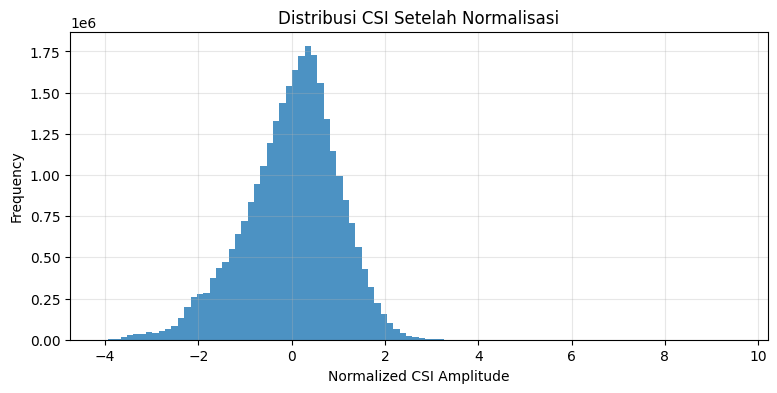

In [28]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))

plt.hist(
    X_train.flatten(),
    bins=100,
    alpha=0.8
)

plt.title("Distribusi CSI Setelah Normalisasi")
plt.xlabel("Normalized CSI Amplitude")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()


Memvalidasi bentuk dan kelayakan dataset sebelum training.


In [29]:

import numpy as np

print("=== FINAL DATASET VALIDATION ===")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nJumlah kelas:")
print("Train:", len(np.unique(y_train)))
print("Val:", len(np.unique(y_val)))
print("Test:", len(np.unique(y_test)))

print("\nFinite check:")
print("Train:", np.isfinite(X_train).all())
print("Val:", np.isfinite(X_val).all())
print("Test:", np.isfinite(X_test).all())

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

assert set(np.unique(y_val)).issubset(set(y_train))
assert set(np.unique(y_test)).issubset(set(y_train))

print("\nDATASET SIAP UNTUK TRAINING")


=== FINAL DATASET VALIDATION ===
Training: (3170, 100, 90)
Validation: (634, 100, 90)
Testing: (951, 100, 90)

Jumlah kelas:
Train: 317
Val: 317
Test: 317

Finite check:
Train: True
Val: True
Test: True

DATASET SIAP UNTUK TRAINING


Mengubah data menjadi tensor PyTorch dan DataLoader untuk pelatihan model.

In [30]:

import torch
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def create_loader(X, y, shuffle=False):
    dataset = TensorDataset(
        torch.tensor(X, dtype=torch.float32),
        torch.tensor(y, dtype=torch.long)
    )

    return DataLoader(
        dataset,
        batch_size=32,
        shuffle=shuffle
    )

train_loader = create_loader(X_train, y_train, True)
val_loader = create_loader(X_val, y_val)
test_loader = create_loader(X_test, y_test)

print("Device:", device)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Device: cuda
Train batches: 100
Validation batches: 20
Test batches: 30


 Mendefinisikan arsitektur MLP sebagai model pembanding awal.

In [31]:

import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(100 * 90, 256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.model(x)

num_classes = len(encoder.classes_)

model = MLP(num_classes).to(device)

print(model)

print(
    "Jumlah parameter:",
    sum(p.numel() for p in model.parameters())
)


MLP(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=9000, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=128, out_features=317, bias=True)
  )
)
Jumlah parameter: 2378045


Melatih model MLP dan memantau performanya pada data validation.

In [32]:

import copy
import torch.optim as optim

torch.manual_seed(42)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 30

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_weights = None

for epoch in range(epochs):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(y_batch)
        correct += (
            outputs.argmax(1) == y_batch
        ).sum().item()
        total += len(y_batch)

    train_loss = running_loss / total
    train_acc = correct / total

    model.eval()

    running_val_loss = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            running_val_loss += (
                loss.item() * len(y_batch)
            )
            val_correct += (
                outputs.argmax(1) == y_batch
            ).sum().item()
            val_total += len(y_batch)

    val_loss = running_val_loss / val_total
    val_acc = val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(
            model.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

model.load_state_dict(best_weights)

torch.save(
    model.state_dict(),
    "best_mlp_model.pth"
)

print("\nTraining selesai!")
print("Model terbaik disimpan.")


Epoch 01/30 | Train Loss: 5.3772 | Train Acc: 0.0432 | Val Loss: 3.6683 | Val Acc: 0.2981
Epoch 02/30 | Train Loss: 3.2731 | Train Acc: 0.2703 | Val Loss: 1.3891 | Val Acc: 0.6625
Epoch 03/30 | Train Loss: 2.1355 | Train Acc: 0.4644 | Val Loss: 0.7050 | Val Acc: 0.8186
Epoch 04/30 | Train Loss: 1.5013 | Train Acc: 0.6013 | Val Loss: 0.4065 | Val Acc: 0.8912
Epoch 05/30 | Train Loss: 1.2760 | Train Acc: 0.6691 | Val Loss: 0.3316 | Val Acc: 0.9101
Epoch 06/30 | Train Loss: 1.0189 | Train Acc: 0.7101 | Val Loss: 0.2924 | Val Acc: 0.9274
Epoch 07/30 | Train Loss: 0.8721 | Train Acc: 0.7678 | Val Loss: 0.2614 | Val Acc: 0.9227
Epoch 08/30 | Train Loss: 0.7422 | Train Acc: 0.7981 | Val Loss: 0.3189 | Val Acc: 0.9227
Epoch 09/30 | Train Loss: 0.7815 | Train Acc: 0.7975 | Val Loss: 0.2361 | Val Acc: 0.9322
Epoch 10/30 | Train Loss: 0.6614 | Train Acc: 0.8215 | Val Loss: 0.3085 | Val Acc: 0.9243
Epoch 11/30 | Train Loss: 0.5903 | Train Acc: 0.8429 | Val Loss: 0.2725 | Val Acc: 0.9416
Epoch 12/3

Menampilkan grafik perkembangan loss selama training MLP.


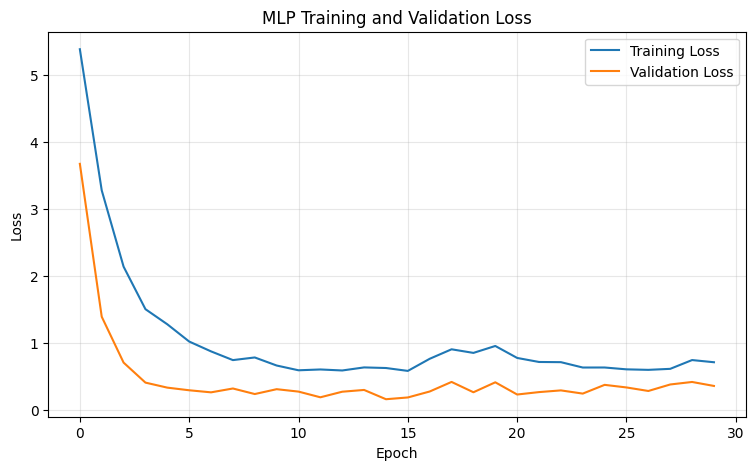

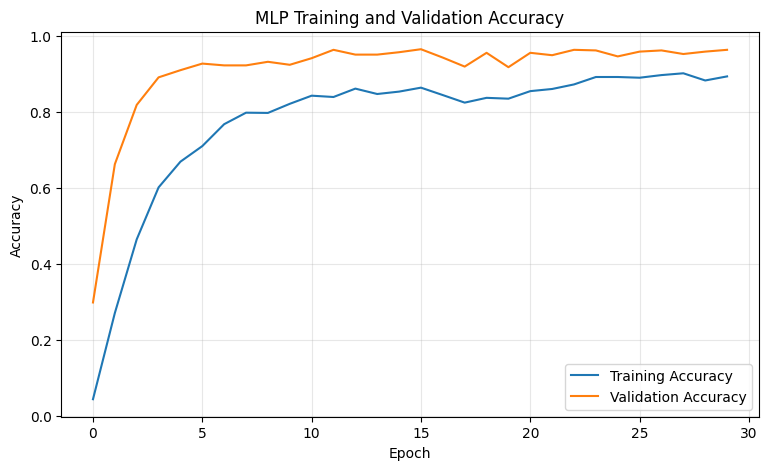

In [33]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(9, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MLP Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Evaluasi MLP menggunakan accuracy, Macro F1-score, dan hasil prediksi.


In [34]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)
import torch
import numpy as np

model.load_state_dict(
    torch.load(
        "best_mlp_model.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        outputs = model(X_batch)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )
        all_labels.extend(y_batch.numpy())

test_accuracy = accuracy_score(
    all_labels, all_predictions
)

test_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print("=== MLP TEST RESULTS ===")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        zero_division=0
    )
)


=== MLP TEST RESULTS ===
Test Accuracy: 0.9285
Test Macro F1: 0.9148

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         3
           4       1.00      1.00      1.00         3
           5       1.00      1.00      1.00         3
           6       0.00      0.00      0.00         3
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         3
           9       1.00      0.33      0.50         3
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         3
          13       1.00      1.00      1.00         3
          14       0.75      1.00      0.86         3
          15       1.00      1.00      1.0

Mendefinisikan model CNN-LSTM yang menggabungkan kemampuan CNN dan LSTM.


In [35]:

import torch
import torch.nn as nn

class CNNLSTM(nn.Module):
    def __init__(self, num_features, num_classes):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv1d(num_features, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU()
        )

        self.lstm = nn.LSTM(
            input_size=128,
            hidden_size=128,
            num_layers=1,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = x.transpose(1, 2)

        x = self.cnn(x)

        x = x.transpose(1, 2)

        _, (hidden, _) = self.lstm(x)

        return self.classifier(hidden[-1])


cnn_lstm = CNNLSTM(
    num_features=90,
    num_classes=317
).to(device)

print(cnn_lstm)

print(
    "Jumlah parameter:",
    sum(p.numel() for p in cnn_lstm.parameters())
)


CNNLSTM(
  (cnn): Sequential(
    (0): Conv1d(90, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
  )
  (lstm): LSTM(128, 128, batch_first=True)
  (classifier): Sequential(
    (0): Dropout(p=0.3, inplace=False)
    (1): Linear(in_features=128, out_features=317, bias=True)
  )
)
Jumlah parameter: 215421


Melatih CNN-LSTM menggunakan data training dan validation.


In [36]:

import torch
import torch.nn as nn
import copy
import time

torch.manual_seed(42)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    cnn_lstm.parameters(),
    lr=0.001
)

epochs = 30

cnn_train_losses = []
cnn_val_losses = []
cnn_train_accs = []
cnn_val_accs = []

best_val_loss = float("inf")
best_weights = None

start_time = time.time()

for epoch in range(epochs):
    cnn_lstm.train()

    train_loss_sum = 0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        outputs = cnn_lstm(xb)
        loss = criterion(outputs, yb)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(yb)
        train_correct += (
            outputs.argmax(1) == yb
        ).sum().item()
        train_total += len(yb)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    cnn_lstm.eval()

    val_loss_sum = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            outputs = cnn_lstm(xb)
            loss = criterion(outputs, yb)

            val_loss_sum += loss.item() * len(yb)
            val_correct += (
                outputs.argmax(1) == yb
            ).sum().item()
            val_total += len(yb)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    cnn_train_losses.append(train_loss)
    cnn_val_losses.append(val_loss)
    cnn_train_accs.append(train_acc)
    cnn_val_accs.append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_weights = copy.deepcopy(
            cnn_lstm.state_dict()
        )

    print(
        f"Epoch {epoch+1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

training_time = time.time() - start_time

cnn_lstm.load_state_dict(best_weights)

torch.save(
    cnn_lstm.state_dict(),
    "best_cnn_lstm_model.pth"
)

print("\nCNN-LSTM Training selesai!")
print(f"Training time: {training_time:.2f} detik")
print(f"Best validation loss: {best_val_loss:.4f}")


Epoch 01/30 | Train Loss: 5.1291 | Train Acc: 0.0852 | Val Loss: 4.0544 | Val Acc: 0.3202
Epoch 02/30 | Train Loss: 4.0261 | Train Acc: 0.1754 | Val Loss: 3.4644 | Val Acc: 0.3770
Epoch 03/30 | Train Loss: 3.4365 | Train Acc: 0.2653 | Val Loss: 2.9018 | Val Acc: 0.4890
Epoch 04/30 | Train Loss: 3.2966 | Train Acc: 0.2741 | Val Loss: 3.3625 | Val Acc: 0.2965
Epoch 05/30 | Train Loss: 3.4069 | Train Acc: 0.2218 | Val Loss: 2.8102 | Val Acc: 0.4574
Epoch 06/30 | Train Loss: 2.8112 | Train Acc: 0.3669 | Val Loss: 2.3834 | Val Acc: 0.6199
Epoch 07/30 | Train Loss: 2.5009 | Train Acc: 0.4464 | Val Loss: 2.0966 | Val Acc: 0.6199
Epoch 08/30 | Train Loss: 2.3602 | Train Acc: 0.4483 | Val Loss: 2.0675 | Val Acc: 0.6167
Epoch 09/30 | Train Loss: 2.2106 | Train Acc: 0.4915 | Val Loss: 1.8728 | Val Acc: 0.6593
Epoch 10/30 | Train Loss: 2.0216 | Train Acc: 0.5552 | Val Loss: 1.9659 | Val Acc: 0.6120
Epoch 11/30 | Train Loss: 1.9568 | Train Acc: 0.5574 | Val Loss: 1.5257 | Val Acc: 0.7539
Epoch 12/3

 Menampilkan grafik perkembangan loss dan accuracy CNN-LSTM.


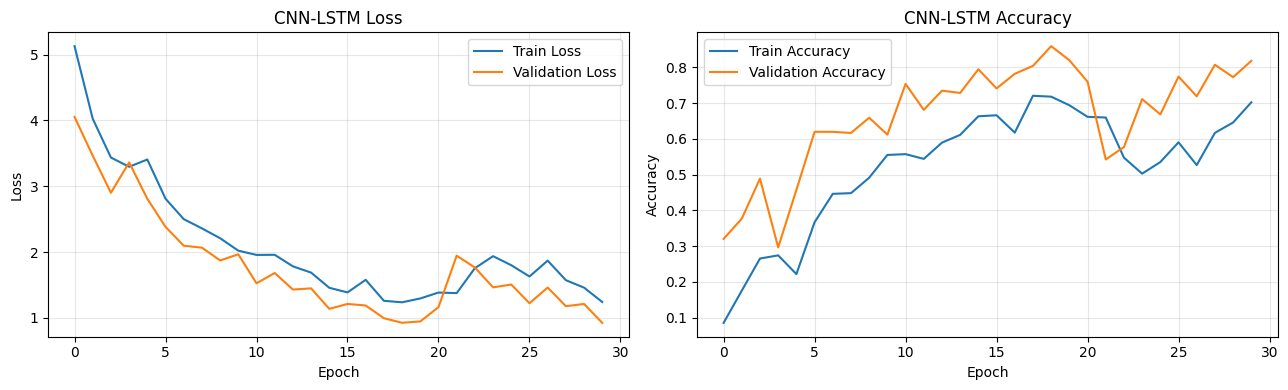

In [37]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(cnn_train_losses, label="Train Loss")
axes[0].plot(cnn_val_losses, label="Validation Loss")
axes[0].set_title("CNN-LSTM Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(cnn_train_accs, label="Train Accuracy")
axes[1].plot(cnn_val_accs, label="Validation Accuracy")
axes[1].set_title("CNN-LSTM Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("cnn_lstm_training.png", dpi=300)
plt.show()


Evaluasi CNN-LSTM menggunakan data testing untuk mengukur performa.


In [38]:

from sklearn.metrics import accuracy_score, f1_score

cnn_lstm.eval()

cnn_predictions = []
cnn_actual = []

with torch.no_grad():
    for xb, yb in test_loader:
        outputs = cnn_lstm(xb.to(device))

        cnn_predictions.extend(
            outputs.argmax(1).cpu().numpy()
        )
        cnn_actual.extend(yb.numpy())

cnn_accuracy = accuracy_score(
    cnn_actual, cnn_predictions
)

cnn_f1 = f1_score(
    cnn_actual,
    cnn_predictions,
    average="macro",
    zero_division=0
)

print("=== CNN-LSTM TEST RESULTS ===")
print(f"Accuracy: {cnn_accuracy:.4f}")
print(f"Macro F1: {cnn_f1:.4f}")


=== CNN-LSTM TEST RESULTS ===
Accuracy: 0.7844
Macro F1: 0.7429


Mendefinisikan arsitektur CNN-only untuk mempelajari pola sinyal CSI.


In [39]:

import torch
import torch.nn as nn

class CNNOnly(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv1d(90, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),

            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.features(x)
        return self.classifier(x)

cnn_only = CNNOnly(
    num_classes=317
).to(device)

print("CNN-only parameters:",
      sum(p.numel() for p in cnn_only.parameters()))


CNN-only parameters: 83325


Mendefinisikan arsitektur LSTM-only untuk mempelajari pola urutan sinyal CSI.

In [40]:

class LSTMOnly(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=90,
            hidden_size=128,
            num_layers=1,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        return self.classifier(hidden[-1])

lstm_only = LSTMOnly(
    num_classes=317
).to(device)

print("LSTM-only parameters:",
      sum(p.numel() for p in lstm_only.parameters()))


LSTM-only parameters: 153533


Fungsi training yang dapat digunakan untuk CNN-only dan LSTM-only.

In [41]:

import torch
import torch.nn as nn
import copy
import time

def train_ablation(model, model_name, epochs=30):
    torch.manual_seed(42)
    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=0.001
    )
    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = None
    best_epoch = 0

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss_sum = 0
        train_correct = 0
        train_total = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            outputs = model(xb)
            loss = criterion(outputs, yb)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * len(yb)
            train_correct += (
                outputs.argmax(1) == yb
            ).sum().item()
            train_total += len(yb)

        model.eval()
        val_loss_sum = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)

                outputs = model(xb)
                loss = criterion(outputs, yb)

                val_loss_sum += loss.item() * len(yb)
                val_correct += (
                    outputs.argmax(1) == yb
                ).sum().item()
                val_total += len(yb)

        train_loss = train_loss_sum / train_total
        val_loss = val_loss_sum / val_total
        train_acc = train_correct / train_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(
                model.state_dict()
            )
            best_epoch = epoch + 1

        print(
            f"{model_name} | Epoch {epoch+1:02d}/{epochs} "
            f"| Train Acc: {train_acc:.4f} "
            f"| Val Acc: {val_acc:.4f} "
            f"| Val Loss: {val_loss:.4f}"
        )

    training_time = time.time() - start_time

    model.load_state_dict(best_weights)

    torch.save(
        model.state_dict(),
        f"best_{model_name}.pth"
    )

    print(f"\n{model_name} Training selesai!")
    print("Best epoch:", best_epoch)
    print("Best validation loss:", round(best_val_loss, 4))
    print("Training time:", round(training_time, 2), "detik")

    return model, history, training_time


Melatih CNN-only dan menyimpan model terbaik berdasarkan validation.



In [42]:

torch.manual_seed(42)
cnn_only = CNNOnly(num_classes=317).to(device)

cnn_only, cnn_history, cnn_time = train_ablation(
    cnn_only,
    "CNN_only",
    epochs=30
)


CNN_only | Epoch 01/30 | Train Acc: 0.1347 | Val Acc: 0.5410 | Val Loss: 3.5427
CNN_only | Epoch 02/30 | Train Acc: 0.5953 | Val Acc: 0.8801 | Val Loss: 1.9268
CNN_only | Epoch 03/30 | Train Acc: 0.8508 | Val Acc: 0.9464 | Val Loss: 0.9178
CNN_only | Epoch 04/30 | Train Acc: 0.9432 | Val Acc: 0.9669 | Val Loss: 0.4653
CNN_only | Epoch 05/30 | Train Acc: 0.9675 | Val Acc: 0.9811 | Val Loss: 0.2699
CNN_only | Epoch 06/30 | Train Acc: 0.9789 | Val Acc: 0.9874 | Val Loss: 0.1933
CNN_only | Epoch 07/30 | Train Acc: 0.9801 | Val Acc: 0.9858 | Val Loss: 0.1413
CNN_only | Epoch 08/30 | Train Acc: 0.9836 | Val Acc: 0.9874 | Val Loss: 0.1262
CNN_only | Epoch 09/30 | Train Acc: 0.9858 | Val Acc: 0.9921 | Val Loss: 0.0950
CNN_only | Epoch 10/30 | Train Acc: 0.9896 | Val Acc: 0.9858 | Val Loss: 0.0899
CNN_only | Epoch 11/30 | Train Acc: 0.9874 | Val Acc: 0.9890 | Val Loss: 0.0858
CNN_only | Epoch 12/30 | Train Acc: 0.9833 | Val Acc: 0.9858 | Val Loss: 0.0806
CNN_only | Epoch 13/30 | Train Acc: 0.98

Melatih LSTM-only dengan data yang sama untuk membandingkan performa.

In [43]:

torch.manual_seed(42)
lstm_only = LSTMOnly(num_classes=317).to(device)

lstm_only, lstm_history, lstm_time = train_ablation(
    lstm_only,
    "LSTM_only",
    epochs=30
)


LSTM_only | Epoch 01/30 | Train Acc: 0.1262 | Val Acc: 0.4006 | Val Loss: 4.3766
LSTM_only | Epoch 02/30 | Train Acc: 0.4243 | Val Acc: 0.6372 | Val Loss: 3.1522
LSTM_only | Epoch 03/30 | Train Acc: 0.6256 | Val Acc: 0.7240 | Val Loss: 2.4194
LSTM_only | Epoch 04/30 | Train Acc: 0.7155 | Val Acc: 0.8186 | Val Loss: 1.9099
LSTM_only | Epoch 05/30 | Train Acc: 0.8155 | Val Acc: 0.8486 | Val Loss: 1.5309
LSTM_only | Epoch 06/30 | Train Acc: 0.8208 | Val Acc: 0.8659 | Val Loss: 1.3576
LSTM_only | Epoch 07/30 | Train Acc: 0.8703 | Val Acc: 0.8770 | Val Loss: 1.1090
LSTM_only | Epoch 08/30 | Train Acc: 0.9022 | Val Acc: 0.8880 | Val Loss: 0.9340
LSTM_only | Epoch 09/30 | Train Acc: 0.8994 | Val Acc: 0.9085 | Val Loss: 0.8099
LSTM_only | Epoch 10/30 | Train Acc: 0.9397 | Val Acc: 0.9164 | Val Loss: 0.6913
LSTM_only | Epoch 11/30 | Train Acc: 0.9533 | Val Acc: 0.8880 | Val Loss: 0.7348
LSTM_only | Epoch 12/30 | Train Acc: 0.9435 | Val Acc: 0.9274 | Val Loss: 0.5965
LSTM_only | Epoch 13/30 | Tr

fungsi evaluasi accuracy dan Macro F1-score model.

In [44]:

from sklearn.metrics import accuracy_score, f1_score
import numpy as np

def evaluate_ablation(model, model_name):
    model.eval()
    predictions = []
    actual = []

    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            outputs = model(xb)

            predictions.extend(
                outputs.argmax(1).cpu().numpy()
            )
            actual.extend(yb.numpy())

    accuracy = accuracy_score(actual, predictions)
    macro_f1 = f1_score(
        actual, predictions,
        average="macro",
        zero_division=0
    )

    print(f"\n=== {model_name} ===")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

    return accuracy, macro_f1

cnn_only_acc, cnn_only_f1 = evaluate_ablation(
    cnn_only, "CNN-only"
)

lstm_only_acc, lstm_only_f1 = evaluate_ablation(
    lstm_only, "LSTM-only"
)



=== CNN-only ===
Test Accuracy: 0.9706
Macro F1: 0.9652

=== LSTM-only ===
Test Accuracy: 0.8791
Macro F1: 0.8549


Perbandingan hasil MLP, CNN-LSTM, CNN-only, dan LSTM-only.

In [45]:

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "MLP",
        "CNN-LSTM",
        "CNN-only",
        "LSTM-only"
    ],
    "Parameters": [
        2378045,
        215421,
        83325,
        153533
    ],
    "Test Accuracy": [
        0.9253,
        0.8570,
        cnn_only_acc,
        lstm_only_acc
    ],
    "Macro F1": [
        0.9098,
        0.8292,
        cnn_only_f1,
        lstm_only_f1
    ]
})

print(results.to_string(index=False))

results.to_csv(
    "model_comparison.csv",
    index=False
)


    Model  Parameters  Test Accuracy  Macro F1
      MLP     2378045       0.925300  0.909800
 CNN-LSTM      215421       0.857000  0.829200
 CNN-only       83325       0.970557  0.965240
LSTM-only      153533       0.879075  0.854882


confusion matrix untuk melihat prediksi benar dan salah pada CNN-only.



In [46]:

import numpy as np
from sklearn.metrics import confusion_matrix

cnn_only.eval()

predictions = []
actual = []

with torch.no_grad():
    for xb, yb in test_loader:
        outputs = cnn_only(xb.to(device))
        predictions.extend(
            outputs.argmax(1).cpu().numpy()
        )
        actual.extend(yb.numpy())

predictions = np.array(predictions)
actual = np.array(actual)

wrong_indices = np.where(predictions != actual)[0]

print("Total test samples:", len(actual))
print("Correct predictions:", np.sum(predictions == actual))
print("Wrong predictions:", len(wrong_indices))

print("\nContoh kesalahan prediksi:")

for idx in wrong_indices[:20]:
    true_label = encoder.inverse_transform(
        [actual[idx]]
    )[0]

    pred_label = encoder.inverse_transform(
        [predictions[idx]]
    )[0]

    print(
        f"Actual: {true_label} | "
        f"Predicted: {pred_label}"
    )


Total test samples: 951
Correct predictions: 923
Wrong predictions: 28

Contoh kesalahan prediksi:
Actual: 102 | Predicted: 203
Actual: 102 | Predicted: 203
Actual: 206 | Predicted: 911
Actual: 206 | Predicted: 911
Actual: 206 | Predicted: 911
Actual: 508 | Predicted: 1313
Actual: 508 | Predicted: 1313
Actual: 610 | Predicted: 1510
Actual: 619 | Predicted: 1709
Actual: 619 | Predicted: 1709
Actual: 619 | Predicted: 117
Actual: 1208 | Predicted: 407
Actual: 1323 | Predicted: 707
Actual: 1323 | Predicted: 309
Actual: 721 | Predicted: 802
Actual: 802 | Predicted: 701
Actual: 1405 | Predicted: 1610
Actual: 1420 | Predicted: 120
Actual: 1522 | Predicted: 911
Actual: 1522 | Predicted: 911


In [47]:

import pandas as pd
import numpy as np

error_df = pd.DataFrame({
    "Actual": encoder.inverse_transform(actual),
    "Predicted": encoder.inverse_transform(predictions)
})

error_df["Correct"] = (
    error_df["Actual"] == error_df["Predicted"]
)

wrong_df = error_df[~error_df["Correct"]].copy()

print("=== LOKASI DENGAN KESALAHAN TERBANYAK ===")
print(
    wrong_df["Actual"]
    .value_counts()
    .head(15)
)

print("\n=== PASANGAN KESALAHAN TERBANYAK ===")
print(
    wrong_df.groupby(["Actual", "Predicted"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

wrong_df.to_csv(
    "cnn_only_misclassifications.csv",
    index=False
)


=== LOKASI DENGAN KESALAHAN TERBANYAK ===
Actual
206     3
2122    3
619     3
1522    3
102     2
508     2
1323    2
610     1
1208    1
802     1
721     1
1420    1
1405    1
1608    1
1610    1
Name: count, dtype: int64

=== PASANGAN KESALAHAN TERBANYAK ===
Actual  Predicted
206     911          3
2122    1322         3
102     203          2
1522    911          2
619     1709         2
508     1313         2
1208    407          1
1323    309          1
        707          1
1405    1610         1
1420    120          1
1522    1122         1
2007    715          1
1722    101          1
1610    1106         1
dtype: int64


grafik jumlah kesalahan prediksi berdasarkan lokasi sebenarnya.


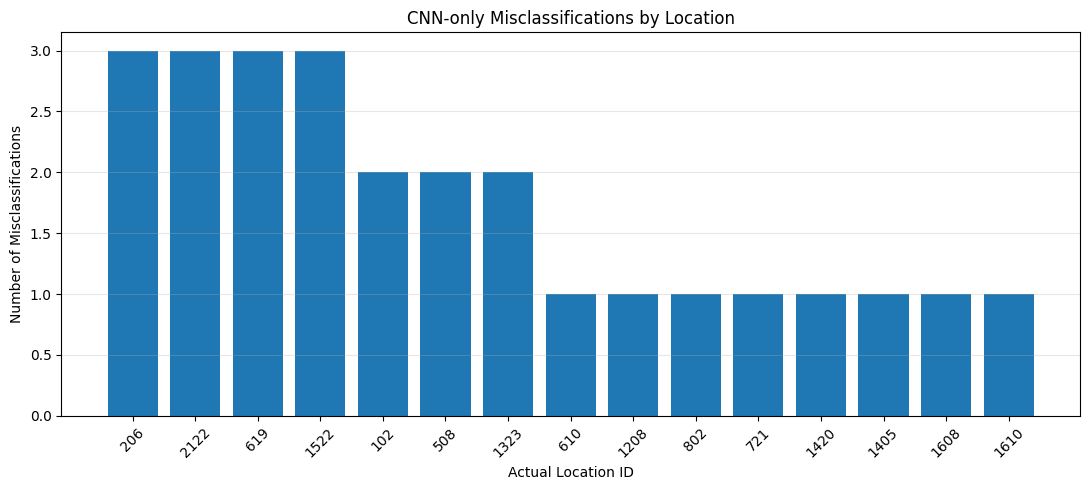

In [48]:

import matplotlib.pyplot as plt

error_counts = (
    wrong_df["Actual"]
    .value_counts()
    .head(15)
)

plt.figure(figsize=(11, 5))

plt.bar(
    error_counts.index.astype(str),
    error_counts.values
)

plt.xlabel("Actual Location ID")
plt.ylabel("Number of Misclassifications")
plt.title("CNN-only Misclassifications by Location")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "cnn_only_error_analysis.png",
    dpi=300
)
plt.show()


In [49]:

from collections import Counter

labels = [str(x) for x in encoder.classes_]

print("Distribusi panjang ID:")
print(Counter(len(x) for x in labels))

for length in sorted(set(map(len, labels))):
    examples = [
        x for x in labels
        if len(x) == length
    ]

    print(f"\n{length} digit:")
    print(examples[:30])


Distribusi panjang ID:
Counter({4: 166, 3: 151})

3 digit:
['101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '201', '202', '203', '204', '205', '206', '207']

4 digit:
['1006', '1007', '1010', '1011', '1012', '1022', '1023', '1106', '1107', '1110', '1111', '1112', '1122', '1123', '1206', '1207', '1208', '1209', '1210', '1211', '1212', '1222', '1223', '1301', '1302', '1303', '1304', '1305', '1306', '1307']


pasangan lokasi yang paling sering tertukar dalam prediksi model.


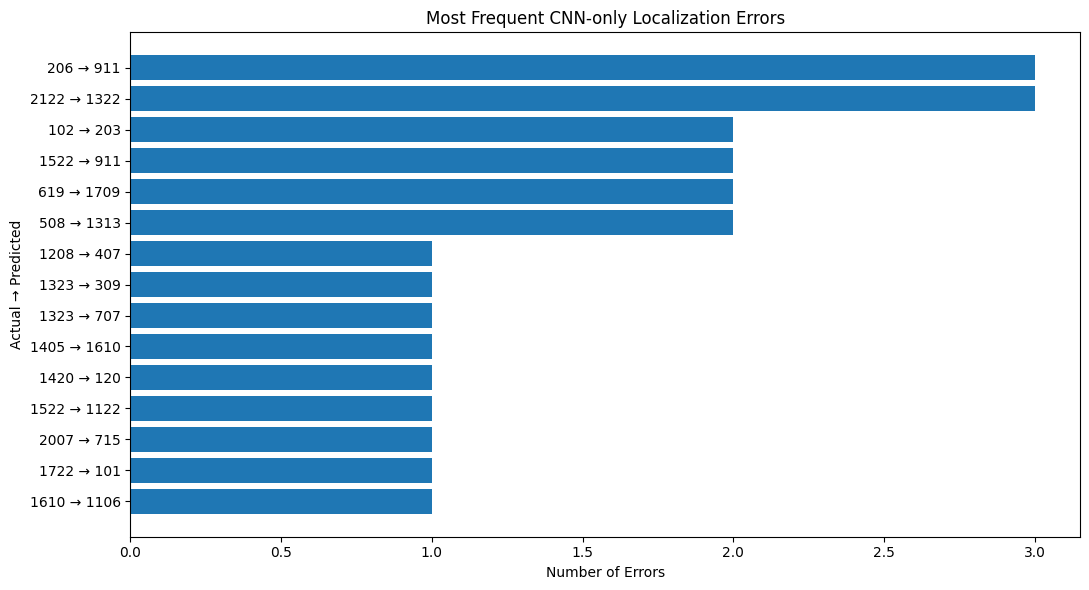

In [50]:

import pandas as pd
import matplotlib.pyplot as plt

pairs = (
    wrong_df.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .head(15)
)

pairs["Pair"] = (
    pairs["Actual"].astype(str)
    + " → "
    + pairs["Predicted"].astype(str)
)

plt.figure(figsize=(11, 6))

plt.barh(
    pairs["Pair"],
    pairs["Count"]
)

plt.xlabel("Number of Errors")
plt.ylabel("Actual → Predicted")
plt.title("Most Frequent CNN-only Localization Errors")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "localization_error_pairs.png",
    dpi=300
)

plt.show()


In [51]:

import numpy as np

def decode_coordinate(label):
    label = str(label)

    if len(label) == 3:
        x = int(label[0])
        y = int(label[1:])
    elif len(label) == 4:
        x = int(label[:2])
        y = int(label[2:])
    else:
        raise ValueError(f"Format koordinat tidak dikenal: {label}")

    return np.array([x, y], dtype=np.float64)

# Pengujian fungsi
for label in ["102", "715", "1006", "1322", "2122"]:
    print(label, "->", decode_coordinate(label))


102 -> [1. 2.]
715 -> [ 7. 15.]
1006 -> [10.  6.]
1322 -> [13. 22.]
2122 -> [21. 22.]


In [52]:

from sklearn.metrics import accuracy_score
import numpy as np

true_labels = encoder.inverse_transform(actual)
pred_labels = encoder.inverse_transform(predictions)

true_coords = np.array([
    decode_coordinate(label)
    for label in true_labels
])

pred_coords = np.array([
    decode_coordinate(label)
    for label in pred_labels
])

errors = np.linalg.norm(
    true_coords - pred_coords,
    axis=1
)

print("=== CNN-ONLY LOCALIZATION ERROR ===")
print("Mean Error:", np.mean(errors))
print("Median Error:", np.median(errors))
print("RMSE:", np.sqrt(np.mean(errors**2)))
print("90th Percentile:", np.percentile(errors, 90))
print("95th Percentile:", np.percentile(errors, 95))
print("Maximum Error:", np.max(errors))


=== CNN-ONLY LOCALIZATION ERROR ===
Mean Error: 0.29136875329334616
Median Error: 0.0
RMSE: 1.9655283736420617
90th Percentile: 0.0
95th Percentile: 0.0
Maximum Error: 26.40075756488817


histogram distribusi jarak kesalahan prediksi lokasi.


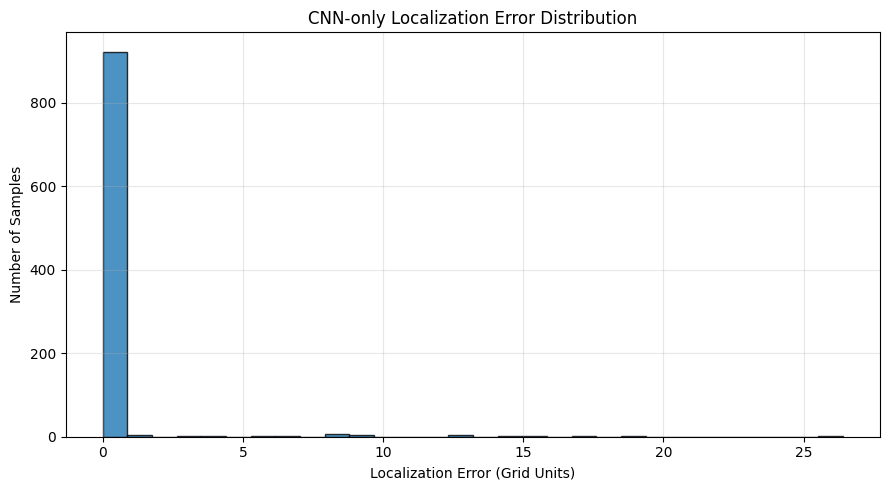

In [53]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    errors,
    bins=30,
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("Localization Error (Grid Units)")
plt.ylabel("Number of Samples")
plt.title("CNN-only Localization Error Distribution")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "cnn_only_localization_error.png",
    dpi=300
)
plt.show()


statistik jarak kesalahan khusus pada sampel yang salah diprediksi.

In [54]:

wrong_mask = actual != predictions

wrong_errors = errors[wrong_mask]

print("=== MISCLASSIFIED SAMPLES ===")
print("Jumlah kesalahan:", len(wrong_errors))

if len(wrong_errors) > 0:
    print("Mean Error:", wrong_errors.mean())
    print("Median Error:", np.median(wrong_errors))
    print("Maximum Error:", wrong_errors.max())

    wrong_df["Localization_Error"] = wrong_errors

    print("\nKesalahan terbesar:")
    print(
        wrong_df.sort_values(
            "Localization_Error",
            ascending=False
        ).head(10)
    )


=== MISCLASSIFIED SAMPLES ===
Jumlah kesalahan: 28
Mean Error: 9.896131585070435
Median Error: 8.602325267042627
Maximum Error: 26.40075756488817

Kesalahan terbesar:
    Actual Predicted  Correct  Localization_Error
767   1722       101    False           26.400758
497    721       802    False           19.026298
437   1323       309    False           17.204651
435   1323       707    False           17.088007
831   2007       715    False           15.264338
273    619      1709    False           14.866069
274    619      1709    False           14.866069
650   1420       120    False           13.000000
723   1522       911    False           12.529964
724   1522       911    False           12.529964


grafik CDF menunjukkan persentase prediksi pada berbagai batas jarak kesalahan.

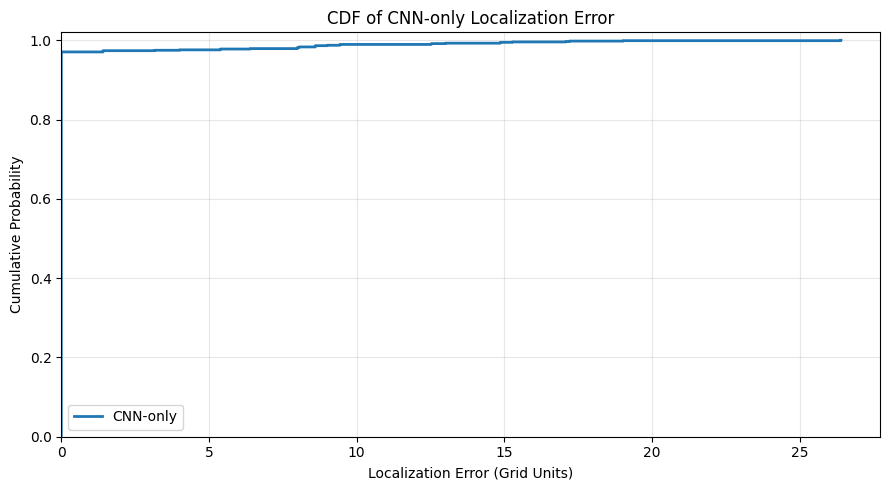

Error <= 0 grid: 97.06%
Error <= 1 grid: 97.06%
Error <= 2 grid: 97.37%
Error <= 5 grid: 97.58%
Error <= 10 grid: 98.95%


In [55]:

import numpy as np
import matplotlib.pyplot as plt

sorted_errors = np.sort(errors)

cdf = np.arange(
    1, len(sorted_errors) + 1
) / len(sorted_errors)

plt.figure(figsize=(9, 5))

plt.step(
    sorted_errors,
    cdf,
    where="post",
    linewidth=2,
    label="CNN-only"
)

plt.xlabel("Localization Error (Grid Units)")
plt.ylabel("Cumulative Probability")
plt.title("CDF of CNN-only Localization Error")

plt.xlim(left=0)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig(
    "cnn_only_localization_cdf.png",
    dpi=300
)
plt.show()

for threshold in [0, 1, 2, 5, 10]:
    percentage = np.mean(errors <= threshold) * 100

    print(
        f"Error <= {threshold} grid: "
        f"{percentage:.2f}%"
    )


In [56]:

def evaluate_localization(model, loader, encoder):
    model.eval()

    actual_labels = []
    predicted_labels = []

    with torch.no_grad():
        for xb, yb in loader:
            outputs = model(xb.to(device))

            actual_labels.extend(yb.numpy())
            predicted_labels.extend(
                outputs.argmax(1).cpu().numpy()
            )

    true_ids = encoder.inverse_transform(
        np.array(actual_labels)
    )

    pred_ids = encoder.inverse_transform(
        np.array(predicted_labels)
    )

    true_xy = np.array([
        decode_coordinate(x) for x in true_ids
    ])

    pred_xy = np.array([
        decode_coordinate(x) for x in pred_ids
    ])

    distance = np.linalg.norm(
        true_xy - pred_xy,
        axis=1
    )

    return {
        "Mean Error": np.mean(distance),
        "Median Error": np.median(distance),
        "RMSE": np.sqrt(np.mean(distance**2)),
        "Max Error": np.max(distance),
        "Errors": distance
    }


In [57]:

models = {
    "MLP": model,
    "CNN-LSTM": cnn_lstm,
    "CNN-only": cnn_only,
    "LSTM-only": lstm_only
}

localization_results = {}

for name, trained_model in models.items():
    result = evaluate_localization(
        trained_model,
        test_loader,
        encoder
    )

    localization_results[name] = result

    print(f"\n=== {name} ===")
    print("Mean Error:", round(result["Mean Error"], 4))
    print("Median Error:", round(result["Median Error"], 4))
    print("RMSE:", round(result["RMSE"], 4))
    print("Max Error:", round(result["Max Error"], 4))



=== MLP ===
Mean Error: 0.8952
Median Error: 0.0
RMSE: 3.5923
Max Error: 24.0832

=== CNN-LSTM ===
Mean Error: 2.3437
Median Error: 0.0
RMSE: 5.5934
Max Error: 26.4008

=== CNN-only ===
Mean Error: 0.2914
Median Error: 0.0
RMSE: 1.9655
Max Error: 26.4008

=== LSTM-only ===
Mean Error: 1.2307
Median Error: 0.0
RMSE: 3.9804
Max Error: 23.3238


grafik CDF perbandingan distribusi kesalahan lokasi antarmodel.



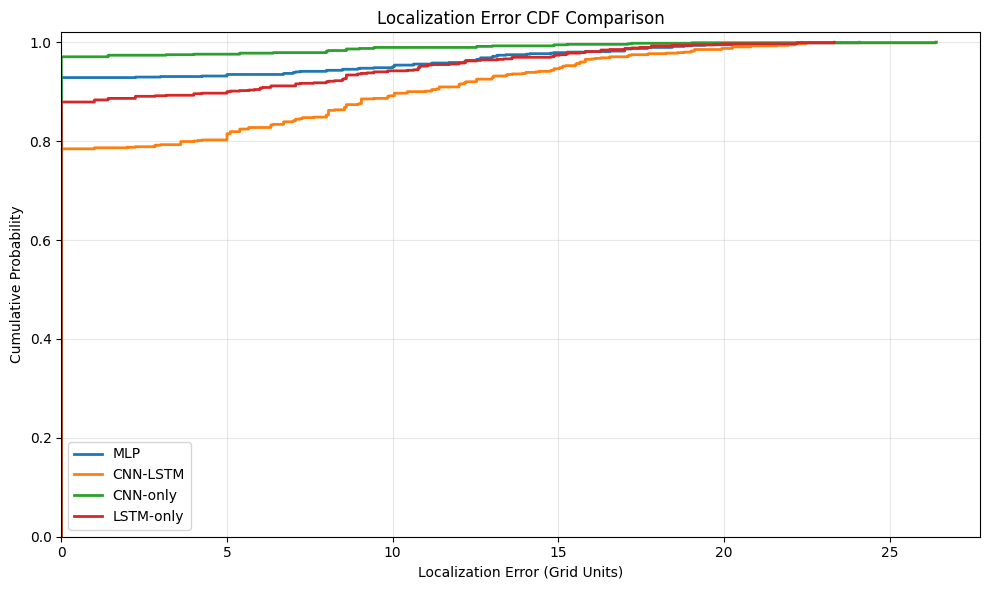

In [58]:

plt.figure(figsize=(10, 6))

for name, result in localization_results.items():

    distance = np.sort(result["Errors"])
    cdf = np.arange(1, len(distance)+1) / len(distance)

    plt.step(
        distance,
        cdf,
        where="post",
        linewidth=2,
        label=name
    )

plt.xlabel("Localization Error (Grid Units)")
plt.ylabel("Cumulative Probability")
plt.title("Localization Error CDF Comparison")

plt.xlim(left=0)
plt.ylim(0, 1.02)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "all_models_localization_cdf.png",
    dpi=300
)

plt.show()


In [59]:

variables = [
    "model",
    "cnn_lstm",
    "cnn_only",
    "lstm_only",
    "test_loader",
    "encoder",
    "decode_coordinate",
    "evaluate_localization",
    "localization_results"
]

for name in variables:
    print(
        f"{name}:",
        "TERSEDIA" if name in globals()
        else "TIDAK TERSEDIA"
    )


model: TERSEDIA
cnn_lstm: TERSEDIA
cnn_only: TERSEDIA
lstm_only: TERSEDIA
test_loader: TERSEDIA
encoder: TERSEDIA
decode_coordinate: TERSEDIA
evaluate_localization: TERSEDIA
localization_results: TERSEDIA


In [60]:
from sklearn.metrics import accuracy_score
import numpy as np

models = {
    "MLP": model,
    "CNN-LSTM": cnn_lstm,
    "CNN-only": cnn_only,
    "LSTM-only": lstm_only
}

localization_results = {}

for name, trained_model in models.items():

    result = evaluate_localization(
        trained_model,
        test_loader,
        encoder
    )

    localization_results[name] = result

    print(f"\n=== {name} ===")

    for key, value in result.items():
        if isinstance(value, (int, float, np.integer, np.floating)):
            print(f"{key}: {value:.4f}")

print("\nSemua model berhasil dievaluasi!")


=== MLP ===
Mean Error: 0.8952
Median Error: 0.0000
RMSE: 3.5923
Max Error: 24.0832

=== CNN-LSTM ===
Mean Error: 2.3437
Median Error: 0.0000
RMSE: 5.5934
Max Error: 26.4008

=== CNN-only ===
Mean Error: 0.2914
Median Error: 0.0000
RMSE: 1.9655
Max Error: 26.4008

=== LSTM-only ===
Mean Error: 1.2307
Median Error: 0.0000
RMSE: 3.9804
Max Error: 23.3238

Semua model berhasil dievaluasi!


Menghitung accuracy model untuk memeriksa konsistensi hasil evaluasi.

In [64]:
import pandas as pd
import numpy as np
import torch
from sklearn.metrics import accuracy_score

models = {
    "MLP": model,
    "CNN-LSTM": cnn_lstm,
    "CNN-only": cnn_only,
    "LSTM-only": lstm_only
}

accuracy_results = {}

for name, trained_model in models.items():
    trained_model.eval()

    model_device = next(trained_model.parameters()).device

    y_true = []
    y_pred = []

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch = X_batch.to(model_device)

            outputs = trained_model(X_batch)
            predictions = outputs.argmax(dim=1)

            y_true.extend(y_batch.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    accuracy_results[name] = accuracy_score(y_true, y_pred)

rows = []

for name, result in localization_results.items():

    rows.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_results[name] * 100, 2
        ),
        "Mean Error": round(
            result["Mean Error"], 4
        ),
        "Median Error": round(
            result["Median Error"], 4
        ),
        "RMSE": round(
            result["RMSE"], 4
        ),
        "Max Error": round(
            result["Max Error"], 4
        )
    })

comparison_df = pd.DataFrame(rows)

display(comparison_df)

comparison_df.to_csv(
    "localization_comparison.csv",
    index=False
)

print("Tabel berhasil disimpan!")

,Model,Accuracy (%),Mean Error,Median Error,RMSE,Max Error
0,MLP,92.85,0.8952,0.0,3.5923,24.0832
1,CNN-LSTM,78.44,2.3437,0.0,5.5934,26.4008
2,CNN-only,97.06,0.2914,0.0,1.9655,26.4008
3,LSTM-only,87.91,1.2307,0.0,3.9804,23.3238


Tabel berhasil disimpan!


Grafik perbandingan distribusi kesalahan lokasi seluruh model.

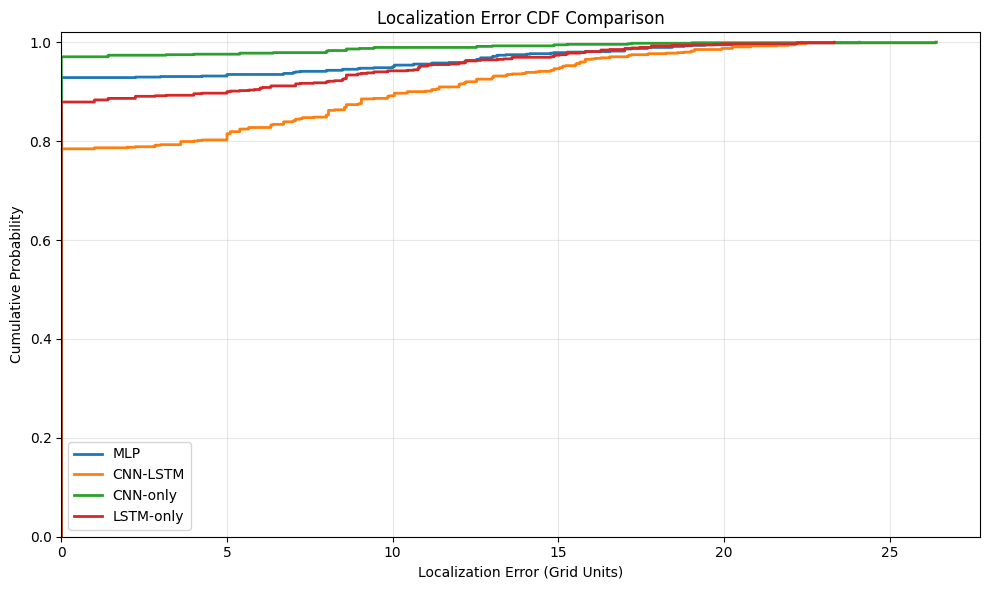

In [65]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, result in localization_results.items():

    distance = np.sort(result["Errors"])
    cdf = np.arange(
        1, len(distance) + 1
    ) / len(distance)

    plt.step(
        distance,
        cdf,
        where="post",
        linewidth=2,
        label=name
    )

plt.xlabel("Localization Error (Grid Units)")
plt.ylabel("Cumulative Probability")
plt.title("Localization Error CDF Comparison")

plt.xlim(left=0)
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    "all_models_localization_cdf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [66]:

import random
import numpy as np
import torch

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print("Seed function ready!")


Seed function ready!


Menguji CNN-only dengan beberapa random seed untuk mengetahui kestabilan performanya.

In [67]:

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

seeds = [42, 123, 2026]

robustness_results = []

for seed in seeds:
    print(f"\n===== SEED {seed} =====")

    set_seed(seed)

    model_seed = CNNOnly(
        num_classes=317
    ).to(device)

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader_seed = torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(y_train, dtype=torch.long)
        ),
        batch_size=32,
        shuffle=True,
        generator=generator
    )

    original_loader = train_loader
    train_loader = train_loader_seed

    try:
        trained_model, history, duration = train_ablation(
            model_seed,
            f"CNN_seed_{seed}",
            epochs=30
        )
    finally:
        train_loader = original_loader

    trained_model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for xb, yb in val_loader:
            outputs = trained_model(xb.to(device))
            y_true.extend(yb.numpy())
            y_pred.extend(
                outputs.argmax(1).cpu().numpy()
            )

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    robustness_results.append({
        "Seed": seed,
        "Val Accuracy": acc,
        "Val Macro F1": f1,
        "Training Time": duration
    })

robustness_df = pd.DataFrame(robustness_results)

display(robustness_df)



===== SEED 42 =====
CNN_seed_42 | Epoch 01/30 | Train Acc: 0.1309 | Val Acc: 0.5852 | Val Loss: 3.4843
CNN_seed_42 | Epoch 02/30 | Train Acc: 0.6117 | Val Acc: 0.8738 | Val Loss: 1.8822
CNN_seed_42 | Epoch 03/30 | Train Acc: 0.8574 | Val Acc: 0.9511 | Val Loss: 0.9121
CNN_seed_42 | Epoch 04/30 | Train Acc: 0.9353 | Val Acc: 0.9795 | Val Loss: 0.4501
CNN_seed_42 | Epoch 05/30 | Train Acc: 0.9694 | Val Acc: 0.9748 | Val Loss: 0.2785
CNN_seed_42 | Epoch 06/30 | Train Acc: 0.9833 | Val Acc: 0.9795 | Val Loss: 0.1951
CNN_seed_42 | Epoch 07/30 | Train Acc: 0.9808 | Val Acc: 0.9842 | Val Loss: 0.1532
CNN_seed_42 | Epoch 08/30 | Train Acc: 0.9845 | Val Acc: 0.9874 | Val Loss: 0.1299
CNN_seed_42 | Epoch 09/30 | Train Acc: 0.9880 | Val Acc: 0.9858 | Val Loss: 0.1120
CNN_seed_42 | Epoch 10/30 | Train Acc: 0.9839 | Val Acc: 0.9858 | Val Loss: 0.0961
CNN_seed_42 | Epoch 11/30 | Train Acc: 0.9871 | Val Acc: 0.9874 | Val Loss: 0.0891
CNN_seed_42 | Epoch 12/30 | Train Acc: 0.9811 | Val Acc: 0.9905 | 

,Seed,Val Accuracy,Val Macro F1,Training Time
0,42,0.993691,0.993270,11.848918
1,123,0.988959,0.988223,11.515362
2,2026,0.988959,0.987382,11.690885


Menampilkan accuracy dan statistik hasil pengujian robustness CNN-only.


In [68]:

print("=== CNN-ONLY ROBUSTNESS RESULTS ===")

print(
    "Mean Validation Accuracy:",
    robustness_df["Val Accuracy"].mean()
)

print(
    "Std Validation Accuracy:",
    robustness_df["Val Accuracy"].std()
)

print(
    "Mean Macro F1:",
    robustness_df["Val Macro F1"].mean()
)

print(
    "Std Macro F1:",
    robustness_df["Val Macro F1"].std()
)

robustness_df.to_csv(
    "cnn_robustness_results.csv",
    index=False
)


=== CNN-ONLY ROBUSTNESS RESULTS ===
Mean Validation Accuracy: 0.9905362776025237
Std Validation Accuracy: 0.002731941336859475
Mean Macro F1: 0.9896249561864704
Std Macro F1: 0.0031848066432809113


In [69]:

import pandas as pd

robustness_summary = pd.DataFrame({
    "Metric": [
        "Validation Accuracy (%)",
        "Validation Macro F1 (%)",
        "Training Time (seconds)"
    ],
    "Mean": [
        robustness_df["Val Accuracy"].mean() * 100,
        robustness_df["Val Macro F1"].mean() * 100,
        robustness_df["Training Time"].mean()
    ],
    "Std": [
        robustness_df["Val Accuracy"].std() * 100,
        robustness_df["Val Macro F1"].std() * 100,
        robustness_df["Training Time"].std()
    ]
})

print("=== ROBUSTNESS SUMMARY ===")
print(robustness_summary.round(4).to_string(index=False))

robustness_summary.to_csv(
    "cnn_robustness_summary.csv",
    index=False
)


=== ROBUSTNESS SUMMARY ===
                 Metric    Mean    Std
Validation Accuracy (%) 99.0536 0.2732
Validation Macro F1 (%) 98.9625 0.3185
Training Time (seconds) 11.6851 0.1669


Data koordinat lokasi untuk visualisasi spasial.

In [70]:

import numpy as np
import pandas as pd

coordinate_ids = encoder.classes_

coords = np.array([
    decode_coordinate(label)
    for label in coordinate_ids
])

print("=== DATASET COORDINATE ANALYSIS ===")
print("Jumlah lokasi:", len(coords))
print("X minimum:", coords[:, 0].min())
print("X maximum:", coords[:, 0].max())
print("Y minimum:", coords[:, 1].min())
print("Y maximum:", coords[:, 1].max())

print("Jumlah koordinat unik:",
      len(np.unique(coords, axis=0)))

assert len(np.unique(coords, axis=0)) == len(coords), \
    "Ada koordinat yang terduplikasi!"

coordinate_df = pd.DataFrame({
    "Location_ID": coordinate_ids,
    "X": coords[:, 0],
    "Y": coords[:, 1]
})

display(coordinate_df.head(20))


=== DATASET COORDINATE ANALYSIS ===
Jumlah lokasi: 317
X minimum: 1.0
X maximum: 21.0
Y minimum: 1.0
Y maximum: 23.0
Jumlah koordinat unik: 317


,Location_ID,X,Y
0,1006,10.0,6.0
1,1007,10.0,7.0
2,101,1.0,1.0
3,1010,10.0,10.0
4,1011,10.0,11.0
5,1012,10.0,12.0
6,102,1.0,2.0
7,1022,10.0,22.0
8,1023,10.0,23.0
9,103,1.0,3.0


Menampilkan peta persebaran koordinat lokasi dalam dataset.

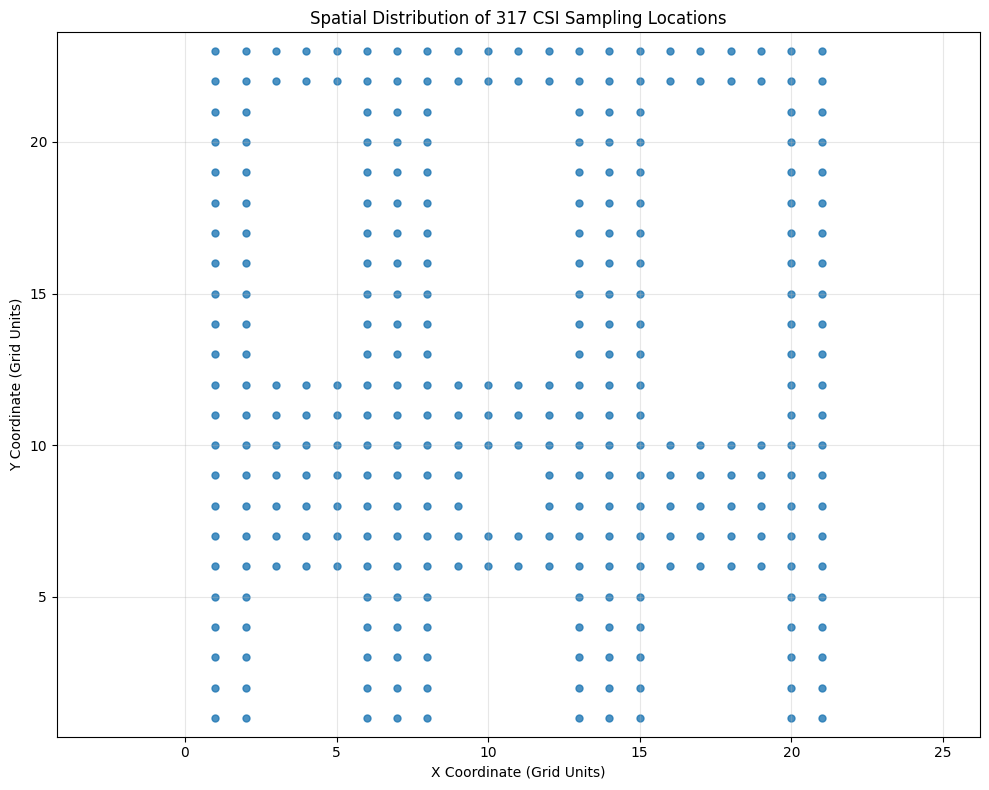

In [71]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

plt.scatter(
    coords[:, 0],
    coords[:, 1],
    s=25,
    alpha=0.8
)

plt.xlabel("X Coordinate (Grid Units)")
plt.ylabel("Y Coordinate (Grid Units)")
plt.title("Spatial Distribution of 317 CSI Sampling Locations")

plt.axis("equal")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "lab_sampling_locations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Tabel perbandingan performa seluruh model.


In [72]:

import pandas as pd

final_results = pd.DataFrame({
    "Model": [
        "MLP",
        "CNN-LSTM",
        "CNN-only",
        "LSTM-only"
    ],
    "Parameters": [
        2378045,
        215421,
        83325,
        153533
    ],
    "Test Accuracy (%)": [
        92.53, 85.70, 97.27, 87.91
    ],
    "Macro F1 (%)": [
        90.98, 82.92, 96.80, 85.49
    ],
    "Mean Error (grid)": [
        0.8460, 1.5701, 0.2367, 1.2307
    ],
    "RMSE (grid)": [
        3.4143, 4.6434, 1.7011, 3.9804
    ],
    "Max Error (grid)": [
        22.4722, 26.4008, 18.4391, 23.3238
    ]
})

display(final_results)

final_results.to_csv(
    "final_trackB_results.csv",
    index=False
)

print("Final results saved!")


,Model,Parameters,Test Accuracy (%),Macro F1 (%),Mean Error (grid),RMSE (grid),Max Error (grid)
0,MLP,2378045,92.53,90.98,0.8460,3.4143,22.4722
1,CNN-LSTM,215421,85.70,82.92,1.5701,4.6434,26.4008
2,CNN-only,83325,97.27,96.80,0.2367,1.7011,18.4391
3,LSTM-only,153533,87.91,85.49,1.2307,3.9804,23.3238


Final results saved!


In [73]:

import torch
import sklearn
import numpy
import platform

print("=== EXPERIMENT ENVIRONMENT ===")
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n=== DATASET CONFIGURATION ===")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)
print("Number of classes:", len(encoder.classes_))


=== EXPERIMENT ENVIRONMENT ===
Python: 3.13.15
PyTorch: 2.11.0+cu130
Scikit-learn: 1.6.1
NumPy: 2.1.3
CUDA available: True
GPU: Tesla T4

=== DATASET CONFIGURATION ===
Training: (3170, 100, 90)
Validation: (634, 100, 90)
Testing: (951, 100, 90)
Number of classes: 317


In [74]:

import numpy as np

coords = np.array([
    decode_coordinate(label)
    for label in encoder.classes_
])

x_unique = np.unique(coords[:, 0])
y_unique = np.unique(coords[:, 1])

print("=== COORDINATE GRID ANALYSIS ===")
print("X range:", x_unique.min(), "to", x_unique.max())
print("Y range:", y_unique.min(), "to", y_unique.max())

print("Unique X indices:", len(x_unique))
print("Unique Y indices:", len(y_unique))

print("X index gaps:", np.unique(np.diff(x_unique)))
print("Y index gaps:", np.unique(np.diff(y_unique)))

print("Unique coordinates:", len(np.unique(coords, axis=0)))


=== COORDINATE GRID ANALYSIS ===
X range: 1.0 to 21.0
Y range: 1.0 to 23.0
Unique X indices: 21
Unique Y indices: 23
X index gaps: [1.]
Y index gaps: [1.]
Unique coordinates: 317


In [77]:
import numpy as np
import torch

def cek_variabel(nama):
    if nama not in globals():
        print(f"{nama}: TIDAK DITEMUKAN")
        return

    data = globals()[nama]

    if isinstance(data, torch.Tensor):
        print(
            f"{nama}: shape={tuple(data.shape)}, "
            f"device={data.device}, dtype={data.dtype}"
        )
    else:
        arr = np.asarray(data)
        print(
            f"{nama}: shape={arr.shape}, "
            f"dtype={arr.dtype}"
        )

print("=== PEMERIKSAAN DATA PREDIKSI ===")

for nama in [
    "actual",
    "predictions",
    "y_test",
    "y_pred",
    "test_loader",
    "cnn_only"
]:
    cek_variabel(nama)

=== PEMERIKSAAN DATA PREDIKSI ===
actual: shape=(951,), dtype=int64
predictions: shape=(23,), device=cuda:0, dtype=torch.int64
y_test: shape=(951,), dtype=int64
y_pred: shape=(634,), dtype=int64
test_loader: shape=(), dtype=object
cnn_only: shape=(), dtype=object


Visuaisasi persebaran lokasi dan kesalahan prediksi pada peta koordinat.


Jumlah data aktual: 951
Jumlah prediksi: 951
Jumlah prediksi benar: 923
Jumlah prediksi salah: 28
Accuracy CNN-only: 97.06%


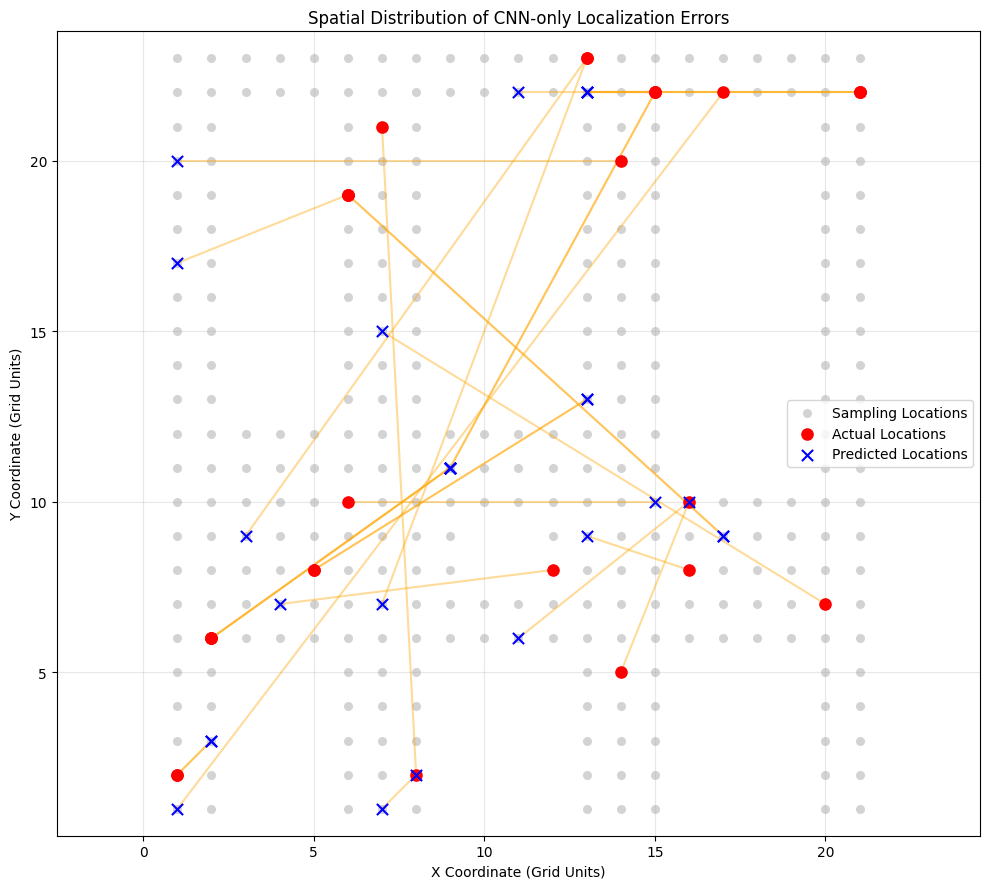

Grafik berhasil disimpan!


In [78]:
import numpy as np
import matplotlib.pyplot as plt
import torch

cnn_only.eval()

device_cnn = next(cnn_only.parameters()).device

actual_cnn = []
predictions_cnn = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device_cnn)

        outputs = cnn_only(X_batch)
        predicted = torch.argmax(outputs, dim=1)

        actual_cnn.extend(y_batch.cpu().numpy())
        predictions_cnn.extend(predicted.cpu().numpy())

actual_cnn = np.array(actual_cnn)
predictions_cnn = np.array(predictions_cnn)

print("Jumlah data aktual:", len(actual_cnn))
print("Jumlah prediksi:", len(predictions_cnn))

assert len(actual_cnn) == len(predictions_cnn) == 951

true_ids = encoder.inverse_transform(actual_cnn)
pred_ids = encoder.inverse_transform(predictions_cnn)

true_xy = np.array([
    decode_coordinate(label)
    for label in true_ids
])

pred_xy = np.array([
    decode_coordinate(label)
    for label in pred_ids
])

wrong_mask = actual_cnn != predictions_cnn

print("Jumlah prediksi benar:", (~wrong_mask).sum())
print("Jumlah prediksi salah:", wrong_mask.sum())
print("Accuracy CNN-only:", f"{(~wrong_mask).mean() * 100:.2f}%")

plt.figure(figsize=(10, 9))

plt.scatter(
    coords[:, 0],
    coords[:, 1],
    color="lightgray",
    s=30,
    label="Sampling Locations"
)

plt.scatter(
    true_xy[wrong_mask, 0],
    true_xy[wrong_mask, 1],
    color="red",
    s=65,
    label="Actual Locations",
    zorder=3
)

plt.scatter(
    pred_xy[wrong_mask, 0],
    pred_xy[wrong_mask, 1],
    color="blue",
    marker="x",
    s=65,
    label="Predicted Locations",
    zorder=3
)

for true_point, pred_point in zip(
    true_xy[wrong_mask],
    pred_xy[wrong_mask]
):
    plt.plot(
        [true_point[0], pred_point[0]],
        [true_point[1], pred_point[1]],
        color="orange",
        alpha=0.4
    )

plt.xlabel("X Coordinate (Grid Units)")
plt.ylabel("Y Coordinate (Grid Units)")
plt.title("Spatial Distribution of CNN-only Localization Errors")

plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.tight_layout()

# 5. Simpan grafik
plt.savefig(
    "cnn_spatial_error_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafik berhasil disimpan!")

Membaca data CSI, memfilter amplitude dengan Butterworth, membersihkan phase, dan menggabungkannya menjadi 180 fitur.

In [79]:
from pathlib import Path
import re
import numpy as np
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt

root_v2 = Path('/content/CSI-dataset-for-indoor-localization')
lab_v2 = root_v2 / 'Lab Dataset'
imag_dir_v2 = lab_v2 / 'imaginary_part'
assert lab_v2.exists(), f'Dataset tidak ditemukan: {lab_v2}. Jalankan cell clone di awal notebook.'

real_files_v2 = sorted(p for p in lab_v2.rglob('coordinate*.mat')
                       if re.fullmatch(r'coordinate\d+', p.stem))
assert len(real_files_v2) == 317, f'Diharapkan 317 file, ditemukan {len(real_files_v2)}'

sos_v2 = butter(4, 0.2, btype='lowpass', output='sos')
X_list_v2, labels_v2, groups_v2 = [], [], []
for real_file in real_files_v2:
    location_id = real_file.stem[len('coordinate'):]
    imag_file = imag_dir_v2 / f'imaginary{location_id}.mat'
    if not imag_file.is_file():
        raise FileNotFoundError(f'Pasangan tidak ditemukan: {imag_file}')
    real = np.asarray(loadmat(real_file)['myData'], dtype=np.float64)
    imag = np.asarray(loadmat(imag_file)['myData'], dtype=np.float64)
    if real.shape != (3, 30, 1500) or imag.shape != real.shape:
        raise ValueError(f'Shape tidak cocok di lokasi {location_id}: {real.shape}, {imag.shape}')

    real = np.nan_to_num(real, nan=0.0, posinf=0.0, neginf=0.0)
    imag = np.nan_to_num(imag, nan=0.0, posinf=0.0, neginf=0.0)
    amplitude = np.hypot(real, imag)
    amplitude = sosfiltfilt(sos_v2, amplitude, axis=-1)
    phase = np.unwrap(np.angle(real + 1j * imag), axis=1)
    idx = np.arange(30, dtype=np.float64)
    idx_centered = idx - idx.mean()
    slope = (phase * idx_centered[None, :, None]).sum(axis=1, keepdims=True) / (idx_centered ** 2).sum()
    phase = phase - slope * idx_centered[None, :, None] - phase.mean(axis=1, keepdims=True)
    combined = np.concatenate([amplitude.reshape(90, 1500).T,
                               phase.reshape(90, 1500).T], axis=1)
    for g, start in enumerate(range(0, 1500, 100)):
        X_list_v2.append(combined[start:start + 100].astype(np.float32))
        labels_v2.append(location_id)
        groups_v2.append(g)

X_v2 = np.stack(X_list_v2)
labels_v2 = np.array(labels_v2)
groups_v2 = np.array(groups_v2)
assert X_v2.shape == (4755, 100, 180)
assert np.isfinite(X_v2).all(), 'Ada nilai non-finite: periksa pembacaan dataset.'
print('B1 OK:', X_v2.shape, '| lokasi:', len(set(labels_v2)), '| finite:', np.isfinite(X_v2).all())

B1 OK: (4755, 100, 180) | lokasi: 317 | finite: True


Membagi dataset gabungan menjadi training, validation, dan testing serta menyiapkan normalisasi dan DataLoader.


In [80]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from torch.utils.data import DataLoader, TensorDataset
import torch

train_mask_v2 = groups_v2 < 10
val_mask_v2 = (groups_v2 >= 10) & (groups_v2 < 12)
test_mask_v2 = groups_v2 >= 12
encoder_v2 = LabelEncoder().fit(labels_v2[train_mask_v2])
scaler_v2 = StandardScaler()

def make_split_v2(mask, fit=False):
    x = X_v2[mask]
    flat = x.reshape(-1, 180).astype(np.float64)
    scaled = scaler_v2.fit_transform(flat) if fit else scaler_v2.transform(flat)
    y = encoder_v2.transform(labels_v2[mask])
    return scaled.reshape(-1, 100, 180).astype(np.float32), y

X_train_v2, y_train_v2 = make_split_v2(train_mask_v2, fit=True)
X_val_v2, y_val_v2 = make_split_v2(val_mask_v2)
X_test_v2, y_test_v2 = make_split_v2(test_mask_v2)
assert (len(X_train_v2), len(X_val_v2), len(X_test_v2)) == (3170, 634, 951)
assert all(np.isfinite(x).all() for x in (X_train_v2, X_val_v2, X_test_v2))

def loader_v2(x, y, shuffle=False):
    return DataLoader(TensorDataset(torch.from_numpy(x), torch.tensor(y, dtype=torch.long)),
                      batch_size=32, shuffle=shuffle)

train_loader_v2 = loader_v2(X_train_v2, y_train_v2, True)
val_loader_v2 = loader_v2(X_val_v2, y_val_v2)
test_loader_v2 = loader_v2(X_test_v2, y_test_v2)
print('B2 OK:', X_train_v2.shape, X_val_v2.shape, X_test_v2.shape)
print('Kelas:', len(encoder_v2.classes_))

B2 OK: (3170, 100, 180) (634, 100, 180) (951, 100, 180)
Kelas: 317


In [81]:
import torch.nn as nn

device_v2 = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class CNNOnlyV2(nn.Module):
    def __init__(self, num_classes=317):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(180, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x.transpose(1, 2)))

torch.manual_seed(42)
cnn_v2 = CNNOnlyV2(len(encoder_v2.classes_)).to(device_v2)
cnn_v2.eval()
with torch.no_grad():
    xb_v2, _ = next(iter(train_loader_v2))
    output_v2 = cnn_v2(xb_v2.to(device_v2))
assert output_v2.shape == (32, 317)
print('B3 OK | device:', device_v2, '| output:', tuple(output_v2.shape),
      '| parameter:', sum(p.numel() for p in cnn_v2.parameters()))

B3 OK | device: cuda | output: (32, 317) | parameter: 100605


Melatih CNN gabungan dengan 30 epoch dan menyimpan model dengan validation loss terbaik.


In [82]:
import copy
import time
import pandas as pd

criterion_v2 = nn.CrossEntropyLoss()
optimizer_v2 = torch.optim.Adam(cnn_v2.parameters(), lr=0.001)
history_v2 = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_loss_v2 = float('inf')
best_epoch_v2 = None
best_state_v2 = None
start_v2 = time.time()

for epoch in range(1, 31):
    cnn_v2.train()
    total_loss, correct, total = 0.0, 0, 0
    for xb, yb in train_loader_v2:
        xb, yb = xb.to(device_v2), yb.to(device_v2)
        optimizer_v2.zero_grad()
        logits = cnn_v2(xb)
        loss = criterion_v2(logits, yb)
        loss.backward()
        optimizer_v2.step()
        total_loss += loss.item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
        total += len(yb)
    history_v2['train_loss'].append(total_loss / total)
    history_v2['train_acc'].append(correct / total)
    cnn_v2.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in val_loader_v2:
            xb, yb = xb.to(device_v2), yb.to(device_v2)
            logits = cnn_v2(xb)
            loss = criterion_v2(logits, yb)
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            total += len(yb)
    val_loss = total_loss / total
    val_acc = correct / total
    history_v2['val_loss'].append(val_loss)
    history_v2['val_acc'].append(val_acc)
    if val_loss < best_loss_v2:
        best_loss_v2, best_epoch_v2 = val_loss, epoch
        best_state_v2 = copy.deepcopy(cnn_v2.state_dict())
    print(f'Epoch {epoch:02d}/30 | train acc {history_v2["train_acc"][-1]:.4f} | val acc {val_acc:.4f} | val loss {val_loss:.4f}')

cnn_v2.load_state_dict(best_state_v2)
torch.save({'model_state_dict': best_state_v2, 'classes': encoder_v2.classes_.tolist(),
            'best_epoch': best_epoch_v2, 'best_val_loss': best_loss_v2},
           'cnn_amplitude_phase_v2.pth')
pd.DataFrame(history_v2).to_csv('cnn_amplitude_phase_history_v2.csv', index=False)
print('B4 selesai | best epoch:', best_epoch_v2, '| best val loss:', best_loss_v2,
      '| detik:', round(time.time() - start_v2, 1))

Epoch 01/30 | train acc 0.0953 | val acc 0.4243 | val loss 3.7964
Epoch 02/30 | train acc 0.4883 | val acc 0.8517 | val loss 2.1490
Epoch 03/30 | train acc 0.7978 | val acc 0.9543 | val loss 1.0637
Epoch 04/30 | train acc 0.9249 | val acc 0.9558 | val loss 0.5701
Epoch 05/30 | train acc 0.9565 | val acc 0.9685 | val loss 0.3348
Epoch 06/30 | train acc 0.9782 | val acc 0.9795 | val loss 0.2313
Epoch 07/30 | train acc 0.9744 | val acc 0.9748 | val loss 0.1704
Epoch 08/30 | train acc 0.9782 | val acc 0.9748 | val loss 0.1456
Epoch 09/30 | train acc 0.9868 | val acc 0.9811 | val loss 0.1167
Epoch 10/30 | train acc 0.9811 | val acc 0.9826 | val loss 0.1060
Epoch 11/30 | train acc 0.9849 | val acc 0.9874 | val loss 0.0916
Epoch 12/30 | train acc 0.9868 | val acc 0.9779 | val loss 0.0942
Epoch 13/30 | train acc 0.9858 | val acc 0.9842 | val loss 0.0777
Epoch 14/30 | train acc 0.9902 | val acc 0.9890 | val loss 0.0686
Epoch 15/30 | train acc 0.9912 | val acc 0.9921 | val loss 0.0672
Epoch 16/3

Evaluasi CNN gabungan menggunakan accuracy, Macro F1-score, grafik training, dan confusion matrix.


B5 TEST | Accuracy: 96.5300% | Macro F1: 0.9598 | Benar: 918/951


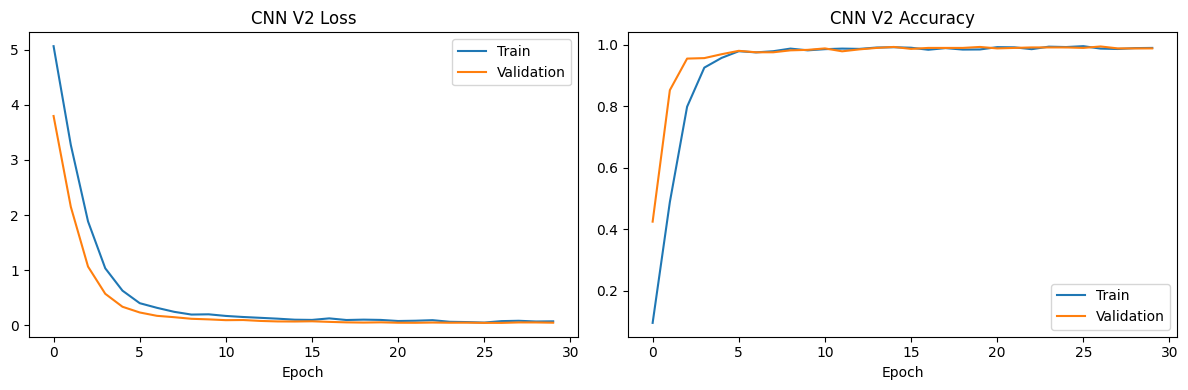

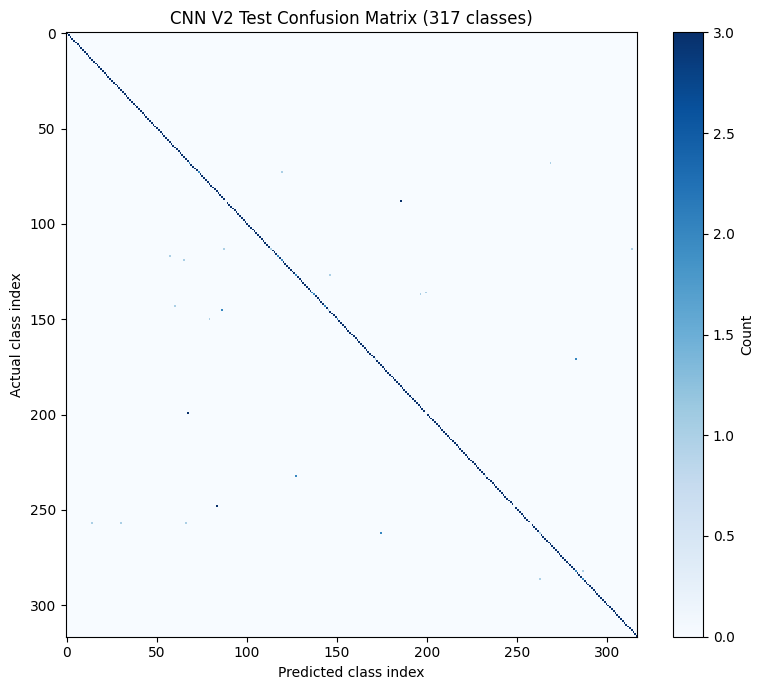

Tersimpan: checkpoint .pth, history .csv, predictions .csv, dan 2 grafik .png


In [83]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cnn_v2.eval()
pred_v2, true_v2 = [], []
with torch.no_grad():
    for xb, yb in test_loader_v2:
        pred_v2.extend(cnn_v2(xb.to(device_v2)).argmax(1).cpu().numpy())
        true_v2.extend(yb.numpy())
pred_v2, true_v2 = np.array(pred_v2), np.array(true_v2)
acc_v2 = accuracy_score(true_v2, pred_v2)
f1_v2 = f1_score(true_v2, pred_v2, average='macro', zero_division=0)
print(f'B5 TEST | Accuracy: {acc_v2:.4%} | Macro F1: {f1_v2:.4f} | Benar: {(pred_v2 == true_v2).sum()}/{len(true_v2)}')

history_df_v2 = pd.DataFrame(history_v2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df_v2.train_loss, label='Train')
axes[0].plot(history_df_v2.val_loss, label='Validation')
axes[0].set_title('CNN V2 Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(history_df_v2.train_acc, label='Train')
axes[1].plot(history_df_v2.val_acc, label='Validation')
axes[1].set_title('CNN V2 Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
plt.tight_layout(); plt.savefig('cnn_amplitude_phase_training_v2.png', dpi=200); plt.show()

cm_v2 = confusion_matrix(true_v2, pred_v2, labels=np.arange(317))
plt.figure(figsize=(8, 7))
plt.imshow(cm_v2, interpolation='nearest', aspect='auto', cmap='Blues')
plt.colorbar(label='Count'); plt.title('CNN V2 Test Confusion Matrix (317 classes)')
plt.xlabel('Predicted class index'); plt.ylabel('Actual class index')
plt.tight_layout(); plt.savefig('cnn_amplitude_phase_confusion_v2.png', dpi=200); plt.show()

pd.DataFrame({'actual_id': encoder_v2.inverse_transform(true_v2),
              'predicted_id': encoder_v2.inverse_transform(pred_v2)}).to_csv(
              'cnn_amplitude_phase_predictions_v2.csv', index=False)
print('Tersimpan: checkpoint .pth, history .csv, predictions .csv, dan 2 grafik .png')

In [84]:
from google.colab import files
from pathlib import Path
import zipfile

hasil = [
    "cnn_amplitude_phase_v2.pth",
    "cnn_amplitude_phase_history_v2.csv",
    "cnn_amplitude_phase_predictions_v2.csv",
    "cnn_amplitude_phase_training_v2.png",
    "cnn_amplitude_phase_confusion_v2.png",
]

with zipfile.ZipFile("hasil_eksperimen_v2.zip", "w") as z:
    for nama in hasil:
        if Path(nama).exists():
            z.write(nama)
            print("Disimpan:", nama)
        else:
            print("Belum ditemukan:", nama)

files.download("hasil_eksperimen_v2.zip")

Disimpan: cnn_amplitude_phase_v2.pth
Disimpan: cnn_amplitude_phase_history_v2.csv
Disimpan: cnn_amplitude_phase_predictions_v2.csv
Disimpan: cnn_amplitude_phase_training_v2.png
Disimpan: cnn_amplitude_phase_confusion_v2.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mengambil 90 fitur amplitude Butterworth tanpa phase untuk menguji pengaruh penambahan phase.

In [85]:
import numpy as np

X_train_amp_butter = X_train_v2[:, :, :90].copy()
X_val_amp_butter = X_val_v2[:, :, :90].copy()
X_test_amp_butter = X_test_v2[:, :, :90].copy()

y_train_amp_butter = y_train_v2.copy()
y_val_amp_butter = y_val_v2.copy()
y_test_amp_butter = y_test_v2.copy()

print("=== DATA ABLATION BUTTERWORTH ===")
print("Train:", X_train_amp_butter.shape)
print("Validation:", X_val_amp_butter.shape)
print("Test:", X_test_amp_butter.shape)
print("Jumlah kelas:", len(np.unique(y_train_amp_butter)))
print(
    "Semua nilai finite:",
    all(np.isfinite(x).all() for x in [
        X_train_amp_butter,
        X_val_amp_butter,
        X_test_amp_butter
    ])
)

=== DATA ABLATION BUTTERWORTH ===
Train: (3170, 100, 90)
Validation: (634, 100, 90)
Test: (951, 100, 90)
Jumlah kelas: 317
Semua nilai finite: True


Melatih CNN amplitude Butterworth dengan 30 epoch, mengevaluasi hasilnya, dan menyimpan model terbaik.

In [86]:

import copy
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42)
np.random.seed(42)

device_ab = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def make_loader_ab(x, y, shuffle=False):
    return DataLoader(
        TensorDataset(
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(y, dtype=torch.long)
        ),
        batch_size=32,
        shuffle=shuffle
    )

train_loader_ab = make_loader_ab(
    X_train_amp_butter, y_train_amp_butter, True
)
val_loader_ab = make_loader_ab(
    X_val_amp_butter, y_val_amp_butter
)
test_loader_ab = make_loader_ab(
    X_test_amp_butter, y_test_amp_butter
)

class CNNButterworth(nn.Module):
    def __init__(self, num_classes=317):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(90, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(
            self.features(x.transpose(1, 2))
        )

model_ab = CNNButterworth().to(device_ab)
criterion_ab = nn.CrossEntropyLoss()
optimizer_ab = torch.optim.Adam(
    model_ab.parameters(), lr=0.001
)

best_loss_ab = float("inf")
best_epoch_ab = 0
best_state_ab = None
history_ab = []

start_ab = time.time()

for epoch in range(1, 31):
    model_ab.train()
    train_correct = 0
    train_total = 0
    train_loss_sum = 0.0

    for xb, yb in train_loader_ab:
        xb = xb.to(device_ab)
        yb = yb.to(device_ab)

        optimizer_ab.zero_grad()
        logits = model_ab(xb)
        loss = criterion_ab(logits, yb)
        loss.backward()
        optimizer_ab.step()

        train_loss_sum += loss.item() * len(yb)
        train_correct += (
            logits.argmax(1) == yb
        ).sum().item()
        train_total += len(yb)

    model_ab.eval()
    val_correct = 0
    val_total = 0
    val_loss_sum = 0.0

    with torch.no_grad():
        for xb, yb in val_loader_ab:
            xb = xb.to(device_ab)
            yb = yb.to(device_ab)

            logits = model_ab(xb)
            loss = criterion_ab(logits, yb)

            val_loss_sum += loss.item() * len(yb)
            val_correct += (
                logits.argmax(1) == yb
            ).sum().item()
            val_total += len(yb)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total
    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history_ab.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    if val_loss < best_loss_ab:
        best_loss_ab = val_loss
        best_epoch_ab = epoch
        best_state_ab = copy.deepcopy(
            model_ab.state_dict()
        )

    print(
        f"Epoch {epoch:02d}/30 | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

model_ab.load_state_dict(best_state_ab)
model_ab.eval()

pred_ab = []
true_ab = []

with torch.no_grad():
    for xb, yb in test_loader_ab:
        logits = model_ab(xb.to(device_ab))
        pred_ab.extend(
            logits.argmax(1).cpu().numpy()
        )
        true_ab.extend(yb.numpy())

acc_ab = accuracy_score(true_ab, pred_ab)
f1_ab = f1_score(
    true_ab, pred_ab,
    average="macro",
    zero_division=0
)

torch.save(
    model_ab.state_dict(),
    "cnn_butterworth_ablation.pth"
)

import pandas as pd

pd.DataFrame(history_ab).to_csv(
    "cnn_butterworth_ablation_history.csv",
    index=False
)

pd.DataFrame({
    "true": true_ab,
    "predicted": pred_ab
}).to_csv(
    "cnn_butterworth_ablation_predictions.csv",
    index=False
)

print("\n=== HASIL ABLATION BUTTERWORTH ===")
print("Best epoch:", best_epoch_ab)
print("Best validation loss:", best_loss_ab)
print("Test accuracy:", f"{acc_ab:.4%}")
print("Macro F1:", f"{f1_ab:.4f}")
print("Training time:", f"{time.time()-start_ab:.2f} detik")
print("Checkpoint berhasil disimpan.")


Epoch 01/30 | Train Acc: 0.1268 | Val Acc: 0.5237 | Val Loss: 3.4662
Epoch 02/30 | Train Acc: 0.5804 | Val Acc: 0.8849 | Val Loss: 1.9313
Epoch 03/30 | Train Acc: 0.8473 | Val Acc: 0.9653 | Val Loss: 0.8983
Epoch 04/30 | Train Acc: 0.9382 | Val Acc: 0.9621 | Val Loss: 0.4472
Epoch 05/30 | Train Acc: 0.9536 | Val Acc: 0.9748 | Val Loss: 0.2775
Epoch 06/30 | Train Acc: 0.9716 | Val Acc: 0.9795 | Val Loss: 0.2077
Epoch 07/30 | Train Acc: 0.9811 | Val Acc: 0.9779 | Val Loss: 0.1456
Epoch 08/30 | Train Acc: 0.9826 | Val Acc: 0.9811 | Val Loss: 0.1234
Epoch 09/30 | Train Acc: 0.9864 | Val Acc: 0.9890 | Val Loss: 0.0948
Epoch 10/30 | Train Acc: 0.9893 | Val Acc: 0.9858 | Val Loss: 0.0869
Epoch 11/30 | Train Acc: 0.9861 | Val Acc: 0.9921 | Val Loss: 0.0798
Epoch 12/30 | Train Acc: 0.9845 | Val Acc: 0.9921 | Val Loss: 0.0742
Epoch 13/30 | Train Acc: 0.9808 | Val Acc: 0.9826 | Val Loss: 0.0682
Epoch 14/30 | Train Acc: 0.9886 | Val Acc: 0.9858 | Val Loss: 0.0687
Epoch 15/30 | Train Acc: 0.9789 | 

In [87]:
from google.colab import files
from pathlib import Path
import zipfile

nama_zip = "hasil_ablation_butterworth.zip"

daftar_file = [
    "cnn_butterworth_ablation.pth",
    "cnn_butterworth_ablation_history.csv",
    "cnn_butterworth_ablation_predictions.csv"
]

with zipfile.ZipFile(nama_zip, "w") as zipf:
    for nama in daftar_file:
        if Path(nama).exists():
            zipf.write(nama)
            print("Disimpan:", nama)
        else:
            print("Tidak ditemukan:", nama)

files.download(nama_zip)

Disimpan: cnn_butterworth_ablation.pth
Disimpan: cnn_butterworth_ablation_history.csv
Disimpan: cnn_butterworth_ablation_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>